# DICE FEST 2026: Trilema Transisi Energi Perkotaan
### Tim BISMILLAH

Notebook ini berisi seluruh solusi kami, dari data mentah sampai file submisi, lalu dari model sampai rekomendasi
kebijakan. Semua angka tebakan dihasilkan oleh kode di notebook ini, dengan seed terkunci dan tanpa data dari luar.

**Gambaran singkat.** Kami memperkirakan lima angka energi untuk setiap kawasan permukiman. Sebelum melatih model, kami
membedah data dan menemukan bahwa porsi bangunan bersih bisa dihitung tepat, adopsi pemanas listrik sudah diketahui
untuk 92% kawasan uji, dan gas total serta intensitas gas (EUI) terikat rumus luas lantai. Bagian yang benar-benar
harus ditebak kami kerjakan dengan fitur yang meniru cara energi dipakai, 41 model yang digabung dengan bobot yang
menyesuaikan, koreksi galat wilayah, dan penyesuaian akhir untuk batas data. Skor leaderboard publik: 0,24913.

| Bagian | Isi |
|---|---|
| 1. Data | rumus tersembunyi di data dan cara data uji dipilih |
| 2. Fitur | ukuran rumah, rata-rata wilayah, kawasan paling mirip, gambaran kawasan |
| 3. Arsitektur | tiga jalur untuk lima target, 41 model, cara menggabungkan |
| 4-5. Pelatihan dan submisi | melatih semua model lalu menyusun file submisi |
| 6. Evaluasi | skor dan perjalanannya |
| 7. Kebijakan | model penjelas, SHAP, peta trilema 330 zona, rekomendasi |
| Lampiran | seluruh kode modul (ditulis ke disk oleh notebook ini) |

**Cara menjalankan.** Pelatihan penuh butuh GPU 16 GB, 16 vCPU, RAM 32 GB, sekitar 20 jam (tiga jalur paralel).
Kalau tebakan semua model sudah ada di folder `WORK`, set `DICEFEST_TRAIN=0` untuk melewati pelatihan; semua bagian lain
tetap dijalankan. File submisi yang dihasilkan selalu dicetak sidik sha256-nya, dan pada run kami hasilnya
`aec745ab...d66e`, sama persis dengan file yang kami kirim.

## 0. Persiapan
Lokasi data, folder kerja, dan versi pustaka yang dipakai.

In [1]:
import os, sys, platform, hashlib, json, subprocess, time
# ---- paths and switches ----
DATA_DIR = os.environ.get("DICEFEST_DATA_DIR", "data/raw")   # train.csv, test.csv, sample_submission.csv
ROOT = os.path.abspath("dicefest_nb")                         # embedded source code + work files
WORK = os.environ.get("DICEFEST_WORK", os.path.join(ROOT, "work"))
OUT_CSV = os.path.join(ROOT, "submission.csv")
TRAIN = os.environ.get("DICEFEST_TRAIN", "1") == "1"   # 0 = skip training and use member predictions already in WORK
os.environ["DICEFEST_DATA_DIR"] = os.path.abspath(DATA_DIR)
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # deterministic cuBLAS, before CUDA starts
os.makedirs(os.path.join(ROOT, "src"), exist_ok=True)
os.makedirs(os.path.join(ROOT, "configs"), exist_ok=True)
for f in ("train.csv", "test.csv", "sample_submission.csv"):
    assert os.path.exists(os.path.join(DATA_DIR, f)), f"missing {f} in {DATA_DIR}"
import numpy, pandas, sklearn, scipy, lightgbm, xgboost, torch, yaml, pyarrow
print("python", platform.python_version())
for m in (numpy, pandas, pyarrow, scipy, sklearn, lightgbm, xgboost, torch):
    print(f"{m.__name__:12s} {m.__version__}")
print("CUDA available:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
EXPECTED = {"numpy": "2.5.4", "pandas": "3.0.6", "scikit-learn": "1.9.1", "lightgbm": "4.7.0",
            "xgboost": "3.4.1", "torch": "2.14.1+cu130"}
print("versions used for the reference run:", EXPECTED)
print("TRAIN =", TRAIN, "| WORK =", WORK)

python 3.12.13
numpy        2.5.4
pandas       3.0.6
pyarrow      26.0.0
scipy        1.18.1
sklearn      1.9.1
lightgbm     4.7.0
xgboost      3.4.1
torch        2.14.1+cu130
CUDA available: True NVIDIA RTX A4000
versions used for the reference run: {'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'lightgbm': '4.7.0', 'xgboost': '3.4.1', 'torch': '2.14.1+cu130'}
TRAIN = False | WORK = /root/Dicefest/final/nbrun_final/work


## Lampiran kode: modul pipeline
Sel-sel berikut menulis modul ke `dicefest_nb/src/` dan konfigurasi ke `dicefest_nb/configs/`, lalu meng-import-nya. Isinya identik dengan `final/src/` dan `final/configs/`. Alur analisis di bagian selanjutnya hanya memanggil fungsi dari modul ini, sehingga setiap sel tetap pendek dan mudah dibaca.

| Modul | Isi |
|---|---|
| `common.py` | pemuatan data, metrik, fitur dasar dan rasio fisik |
| `te.py`, `features_knn.py`, `fb07b.py` | encoding spasial (subzona, zona, sel iklim, jendela sub_n) dan fitur kNN-target, semuanya out-of-fold |
| `train_lib.py`, `nn.py`, `nca.py` | pelatihan anggota: GBM (XGBoost, LightGBM), MLP (PLR, TabM-mini), regresor retrieval NCA |
| `blend.py`, `postprocess.py` | blend NNLS dengan bobot bervariasi dan koreksi residual grup + kNN |
| `adopt_v2.py`, `dup_fix.py` | model adopsi pemanas listrik dan salinan baris duplikat |
| `pipeline.py` | orkestrasi: tahap anggota, adopsi, perakitan submisi |
| `explain.py`, `report.py` | interpretabilitas (TreeSHAP), indeks kebijakan per zona, tabel dan diagram notebook |
| `inference.py`, `metric.py`, `seed.py` | prediksi dari artefak, metrik kompetisi, penguncian seed |
| `configs/members.yaml`, `configs/resid_knn.json` | daftar anggota dan hiperparameternya; bobot koreksi dan parameter post-processing yang dibekukan |

In [2]:
%%writefile dicefest_nb/src/common.py
"""Shared data loading, feature preparation and metric for DICE FEST 2026."""
import os

import numpy as np
import pandas as pd

SEED = 42

TARGET_COLS = [
    "target_macro_gas_kwh",
    "target_macro_elec_kwh",
    "target_eui_gas_kwh_per_sqm",
    "target_clean_building_ratio",
    "target_electric_heating_adoption",
]
SIGMAS = {
    "target_macro_gas_kwh": 151750.04,
    "target_macro_elec_kwh": 41725.37,
    "target_eui_gas_kwh_per_sqm": 40.65,
    "target_clean_building_ratio": 12.49,
    "target_electric_heating_adoption": 7.18,
}
HVAC = [f"hvac_dist_{i:02d}" for i in range(1, 11)]
ERA_MAP = {"High (<0%)": 0, "Medium (0-6%)": 1, "Low (6-18%)": 2, "Very Low (>18%)": 3}


def nrmse(y_true, y_pred, col):
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)) / SIGMAS[col])


def holdout_split(n, frac=0.7, seed=7):
    """Fixed split of the train rows into P (models trained here) and H (holdout for fitting blend weights)."""
    perm = np.random.default_rng(seed).permutation(n)
    return np.sort(perm[: int(frac * n)]), np.sort(perm[int(frac * n):])


DATA_DIR = os.environ.get("DICEFEST_DATA_DIR", "data/raw")  # folder with train.csv, test.csv, sample_submission.csv
_CACHE = {}


def load(cache=None):
    """train / test frames read from DATA_DIR with the pyarrow CSV parser (bit-identical to the parquet cache used
    during development, see env/data_check.json). The argument is kept for API compatibility and ignored."""
    if "tr" not in _CACHE:
        _CACHE["tr"] = pd.read_csv(os.path.join(DATA_DIR, "train.csv"), engine="pyarrow")
        _CACHE["te"] = pd.read_csv(os.path.join(DATA_DIR, "test.csv"), engine="pyarrow")
    return _CACHE["tr"].copy(), _CACHE["te"].copy()


def load_sample():
    return pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"), engine="pyarrow")


def base_features(df, const_cols):
    """Numeric feature frame: encoded strings, id codes, and a few physics-motivated ratios."""
    X = df.drop(columns=[c for c in df.columns if c.startswith("target_")] + ["id"] + const_cols).copy()
    X["bld_dim_18"] = X["bld_dim_18"].map(ERA_MAP).astype("float32")
    X["socio_demog_016"] = (X["socio_demog_016"] == "Urban").astype("float32")
    X["zone_n"] = X.pop("zone_region_id").str[4:].astype("int32")
    X["sub_n"] = X.pop("subzone_id").str[4:].astype("int32")
    A = df["bld_dim_06"]
    X["hvac_rest"] = 100 - df[HVAC].sum(axis=1)
    X["area_per_meter"] = A / df["bld_dim_12"]
    X["area_per_epc"] = A / df["bld_dim_01"]
    X["gea_ratio"] = A / df["bld_dim_03"]
    X["a07_ratio"] = df["bld_dim_07"] / A
    X["a08_ratio"] = df["bld_dim_08"] / A
    X["a05_ratio"] = df["bld_dim_05"] / df["bld_dim_03"]
    X["a04_ratio"] = df["bld_dim_04"] / df["bld_dim_03"]
    X["s002_ratio"] = df["socio_demog_002"] / A
    X["meters_per_epc"] = df["bld_dim_12"] / df["bld_dim_01"]
    X["clean_ratio"] = df["bld_dim_02"] / df["bld_dim_01"]
    return X.astype("float32")


def constant_cols(tr):
    num = tr.select_dtypes("number")
    return [c for c in num.columns if num[c].nunique() <= 1]


Writing dicefest_nb/src/common.py


In [3]:
%%writefile dicefest_nb/src/te.py
"""Out-of-fold group target statistics (hierarchical spatial encodings)."""
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold


def group_stats(fit_keys, fit_vals, apply_keys):
    """Sum and count of `fit_vals` columns per key, looked up for `apply_keys`.

    fit_vals: 2-D array (n_fit, k). Returns (sums (n_apply, k), counts (n_apply,)).
    """
    df = pd.DataFrame(fit_vals)
    df["_k"] = fit_keys
    g = df.groupby("_k", sort=False)
    sums = g.sum()
    cnt = g.size()
    idx = pd.Index(sums.index).get_indexer(apply_keys)
    out_s = np.zeros((len(apply_keys), fit_vals.shape[1]))
    out_c = np.zeros(len(apply_keys))
    ok = idx >= 0
    out_s[ok] = sums.values[idx[ok]]
    out_c[ok] = cnt.values[idx[ok]]
    return out_s, out_c


def oof_group_stats(keys, vals, n_splits=5, seed=42):
    """K-fold out-of-fold sums/counts for every row of one set."""
    s = np.zeros((len(keys), vals.shape[1]))
    c = np.zeros(len(keys))
    for a, b in KFold(n_splits, shuffle=True, random_state=seed).split(keys):
        s[b], c[b] = group_stats(keys[a], vals[a], keys[b])
    return s, c


def window_stats(fit_pos, fit_vals, apply_pos, w, size):
    """Sums/counts over fit rows whose position lies in [p-w, p+w], excluding position p itself.

    Positions are the numeric subzone ids, which are ordered roughly geographically.
    """
    k = fit_vals.shape[1]
    S = np.zeros((size + 2 * w + 2, k))
    C = np.zeros(size + 2 * w + 2)
    np.add.at(S, fit_pos + w + 1, fit_vals)
    np.add.at(C, fit_pos + w + 1, 1.0)
    cS = np.cumsum(S, axis=0)
    cC = np.cumsum(C)
    hi = apply_pos + 2 * w + 1
    lo = apply_pos
    s = cS[hi] - cS[lo] - S[apply_pos + w + 1]
    c = cC[hi] - cC[lo] - C[apply_pos + w + 1]
    return s, c


def oof_window_stats(pos, vals, w, size, n_splits=5, seed=42):
    s = np.zeros((len(pos), vals.shape[1]))
    c = np.zeros(len(pos))
    for a, b in KFold(n_splits, shuffle=True, random_state=seed).split(pos):
        s[b], c[b] = window_stats(pos[a], vals[a], pos[b], w, size)
    return s, c


def stats_to_features(s, c, names, prefix, prior=None, k=0.0):
    """Turn sums/counts into (optionally shrunk) means plus a count column."""
    out = {f"{prefix}_cnt": c}
    for j, n in enumerate(names):
        if prior is None:
            m = np.where(c > 0, s[:, j] / np.maximum(c, 1), np.nan)
        else:
            m = (s[:, j] + k * prior[j]) / (c + k)
        out[f"{prefix}_{n}"] = m
    return pd.DataFrame(out)


Writing dicefest_nb/src/te.py


In [4]:
%%writefile dicefest_nb/src/features_knn.py
"""kNN neighbour statistics within sub_n windows (FB07), shared by train_lib and src/features."""
import numpy as np


def knn_stats(Zf, sf, Vf, Za, sa, W, k, spatial=0.0, exclude_self=None):
    """mean of the value columns Vf over the k fit rows nearest to each apply row (squared distance in Z plus
    spatial * |sub_n diff| / W) among fit rows with |sub_n diff| <= W; also the neighbour count and mean distance.
    exclude_self: for each apply row, the fit-row index to skip (or -1)."""
    o = np.argsort(sf, kind="stable")
    so = sf[o]
    lo, hi = np.searchsorted(so, sa - W, "left"), np.searchsorted(so, sa + W, "right")
    L = max(int((hi - lo).max()), 1)
    chunk = max(256, int(2e7 // (L * (Zf.shape[1] + 1))))
    Vo, Zo, sof = Vf[o], Zf[o], so.astype(float)
    inv = np.empty(len(o), dtype=np.int64)
    inv[o] = np.arange(len(o))
    out = np.full((len(sa), Vf.shape[1]), np.nan)
    cnt, md = np.zeros(len(sa)), np.full(len(sa), np.nan)
    for s in range(0, len(sa), chunk):
        idx = np.arange(s, min(s + chunk, len(sa)))
        valid = np.arange(L)[None, :] < (hi[idx] - lo[idx])[:, None]
        cand = np.where(valid, lo[idx, None] + np.arange(L)[None, :], 0)
        if exclude_self is not None:
            es = exclude_self[idx]
            valid &= ~((es[:, None] >= 0) & (cand == np.where(es >= 0, inv[np.maximum(es, 0)], -1)[:, None]))
        dist = ((Zo[cand] - Za[idx][:, None, :]) ** 2).sum(-1)
        if spatial:
            dist = dist + spatial * np.abs(sof[cand] - sa[idx, None]) / max(W, 1)
        dist = np.where(valid, dist, np.inf)
        kk = min(k, L)
        part = np.argpartition(dist, kk - 1, axis=1)[:, :kk]
        sel = np.take_along_axis(cand, part, 1)
        dsel = np.take_along_axis(dist, part, 1)
        ok = np.isfinite(dsel)
        c = ok.sum(1)
        good = c > 0
        out[idx[good]] = (Vo[sel] * ok[..., None]).sum(1)[good] / c[good, None]
        cnt[idx] = c
        md[idx[good]] = np.where(ok, dsel, 0).sum(1)[good] / c[good]
    return out, cnt, md


Writing dicefest_nb/src/features_knn.py


In [5]:
%%writefile dicefest_nb/src/fb07b.py
"""FB07b: extra kNN-target statistics appended to the FB07 block of train_lib.Data (A/B: src/exp_fb07b.py).

The extra neighbour spaces / windows are the ones the residual correction found useful (src/resid_knn.py CONFIGS):
building era space, building + census PCA space, a 3-feature size space, a very local (W=10) and a wide (W=1000)
window in the full space. Set `d.sp = {name: (Z_train_rows, Z_apply_rows)}` (src/resid_knn.spaces) before use.

The FB07 part comes from Data.knn_features (cached in d.knn_cache_dir, shared with the v16 members); the extra part is
cached separately in d.knn_x_cache_dir. Apply rows are split into blocks that run in parallel threads (numpy releases
the GIL); every row is computed independently, so the values do not depend on the number of threads.
"""
import hashlib
import os
import sys
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from sklearn.model_selection import KFold

sys.path.insert(0, os.path.dirname(__file__))
from common import SEED  # noqa: E402
from features_knn import knn_stats  # noqa: E402
from train_lib import Data  # noqa: E402

EXTRA = (("era", 30, 20, 0.0), ("era", 300, 50, 0.0), ("fc", 300, 50, 0.0), ("full", 10, 10, 0.0),
         ("full", 1000, 100, 0.0), ("small", 30, 20, 0.0))
THREADS = 3  # 8 in development; the values do not depend on it (blocks are independent), only the memory does
BLOCK = 20000  # apply rows per parallel task


def _blocked(configs, Zf, sf, Vf, Za_of, sa_of, n_apply, space_of):
    """knn_stats for every config over blocks of apply rows in parallel threads; returns one result per config"""
    blocks = [np.arange(s, min(s + BLOCK, n_apply)) for s in range(0, n_apply, BLOCK)]

    def one(task):
        cfg, blk = task
        sp_name = space_of(cfg)
        return knn_stats(Zf(sp_name), sf, Vf, Za_of(sp_name, blk), sa_of(blk), cfg[-3], cfg[-2], cfg[-1])

    tasks = [(cfg, blk) for cfg in configs for blk in blocks]
    with ThreadPoolExecutor(THREADS) as ex:
        res = list(ex.map(one, tasks))
    out = []
    for i in range(len(configs)):
        parts = res[i * len(blocks):(i + 1) * len(blocks)]
        out.append(tuple(np.concatenate([p[j] for p in parts]) for j in range(3)))
    return out


class DataP(Data):
    """Data with the FB07 block computed in parallel blocks (same configs and values as Data._knn_features up to
    distance ties); used by the A/B so that both variants share the same, faster FB07 code"""

    def _knn_features(self, fit_idx, apply="oof", inner=5):
        Z, Zt = self.knn_space()
        V = np.c_[np.log(self.V[:, 0]), self.V[:, 3], np.log(self.V[:, 5])]

        def feats(f, rows_apply, test):
            n_apply = len(self.subnt) if test else len(rows_apply)
            res = _blocked([("full",) + c for c in self.KNN_CONFIGS], lambda _: Z[f], self.subn[f], V[f],
                           lambda _, blk: Zt[blk] if test else Z[rows_apply[blk]],
                           lambda blk: self.subnt[blk] if test else self.subn[rows_apply[blk]], n_apply, lambda c: c[0])
            cols = {}
            for (W, k, sp), (v, c, dd) in zip(self.KNN_CONFIGS, res):
                tag = f"knn_w{W}_k{k}" + ("s" if sp else "")
                for j, nm in enumerate(("leui", "lepm", "lgpm")):
                    cols[f"{tag}_{nm}"] = v[:, j]
                cols[f"{tag}_cnt"] = c
                cols[f"{tag}_dist"] = dd
            return pd.DataFrame(cols).astype("float32")

        return _cross_fit(feats, fit_idx, apply, inner)


def _cross_fit(feats, fit_idx, apply, inner):
    """inner-OOF features for fit rows ('oof'), features of test rows ('test') or of train rows (('train', idx))"""
    if isinstance(apply, str) and apply == "oof":
        parts, idx = [], []
        for ia, ib in KFold(inner, shuffle=True, random_state=SEED).split(fit_idx):
            parts.append(feats(fit_idx[ia], fit_idx[ib], False))
            idx.append(ib)
        F = pd.concat(parts, ignore_index=True)
        return F.iloc[np.argsort(np.concatenate(idx), kind="stable")].reset_index(drop=True)
    if isinstance(apply, str) and apply == "test":
        return feats(fit_idx, None, True)
    return feats(fit_idx, apply[1], False)


class DataX(Data):
    """Data whose kNN block is FB07 followed by FB07b (train rows = self.X, apply rows = self.Xt).
    use_x=False switches the extra block off, so one instance serves FB07 and FB07b members alike."""

    def knn_features(self, fit_idx, apply="oof", inner=5):
        F = super().knn_features(fit_idx, apply, inner)
        if not getattr(self, "use_x", True):  # FB07 only (members without the FB07b block, e.g. the v16 kNN members)
            return F
        cdir = getattr(self, "knn_x_cache_dir", None)
        path = None
        if cdir:
            h = hashlib.sha256()
            for arr in (np.asarray(fit_idx), self.subn, self.subnt, self.V[:, [0, 3, 5]]):
                h.update(np.ascontiguousarray(arr).tobytes())
            for name in sorted(self.sp):
                h.update(np.ascontiguousarray(self.sp[name][0][:1000]).tobytes())
            h.update(repr((apply if isinstance(apply, str) else ("train",), inner, EXTRA)).encode())
            if not isinstance(apply, str):
                h.update(np.ascontiguousarray(apply[1]).tobytes())
            path = os.path.join(cdir, h.hexdigest()[:32] + ".parquet")
            if os.path.exists(path):
                return pd.concat([F.reset_index(drop=True), pd.read_parquet(path)], axis=1)
        Fx = self._knn_extra(fit_idx, apply, inner)
        if path:
            os.makedirs(cdir, exist_ok=True)
            tmp = f"{path}.{os.getpid()}.tmp"
            Fx.to_parquet(tmp, index=False)
            os.replace(tmp, path)
        return pd.concat([F.reset_index(drop=True), Fx], axis=1)

    def _knn_extra(self, fit_idx, apply="oof", inner=5):
        V = np.c_[np.log(self.V[:, 0]), self.V[:, 3], np.log(self.V[:, 5])]  # leui, lepm, lgpm

        def feats(f, rows_apply, test):
            n_apply = len(self.subnt) if test else len(rows_apply)
            blocks = [np.arange(s, min(s + BLOCK, n_apply)) for s in range(0, n_apply, BLOCK)]

            def one(task):
                (name, W, k, sp), blk = task
                Ztr, Zte = self.sp[name]
                Za = Zte[blk] if test else Ztr[rows_apply[blk]]
                sa = self.subnt[blk] if test else self.subn[rows_apply[blk]]
                return knn_stats(Ztr[f], self.subn[f], V[f], Za, sa, W, k, sp)

            tasks = [(cfg, blk) for cfg in EXTRA for blk in blocks]
            with ThreadPoolExecutor(THREADS) as ex:
                res = list(ex.map(one, tasks))
            cols, i = {}, 0
            for name, W, k, sp in EXTRA:
                parts = res[i:i + len(blocks)]
                i += len(blocks)
                v = np.concatenate([p[0] for p in parts])
                dd = np.concatenate([p[2] for p in parts])
                tag = f"kx_{name}_w{W}_k{k}"
                for j, nm in enumerate(("leui", "lepm", "lgpm")):
                    cols[f"{tag}_{nm}"] = v[:, j]
                cols[f"{tag}_dist"] = dd
            return pd.DataFrame(cols).astype("float32")

        if isinstance(apply, str) and apply == "oof":
            parts, idx = [], []
            for ia, ib in KFold(inner, shuffle=True, random_state=SEED).split(fit_idx):
                parts.append(feats(fit_idx[ia], fit_idx[ib], False))
                idx.append(ib)
            F = pd.concat(parts, ignore_index=True)
            return F.iloc[np.argsort(np.concatenate(idx), kind="stable")].reset_index(drop=True)
        if isinstance(apply, str) and apply == "test":
            return feats(fit_idx, None, True)
        return feats(fit_idx, apply[1], False)


Writing dicefest_nb/src/fb07b.py


In [6]:
%%writefile dicefest_nb/src/train_lib.py
"""Cross-validated training harness: one call = one (model, target formulation) pair.

Every run writes out-of-fold predictions (oof/<name>.npy) and the fold-averaged test
prediction (pred/<name>.npy) on the *physical* scale of the modelled quantity, so runs
can be blended afterwards.
"""
import os
import sys
import time

import numpy as np
import pandas as pd
from sklearn.model_selection import KFold

sys.path.insert(0, os.path.dirname(__file__))
from common import SEED, TARGET_COLS, base_features, constant_cols, load, nrmse  # noqa: E402
from te import group_stats, oof_group_stats, oof_window_stats, stats_to_features, window_stats  # noqa: E402

N_FOLDS = 5


class Data:
    def __init__(self, cache="cache", n_folds=N_FOLDS):
        tr, te = load(cache)
        const = constant_cols(tr)
        self.X = base_features(tr, const)
        self.Xt = base_features(te, const)
        self.A, self.At = tr["bld_dim_06"].values, te["bld_dim_06"].values
        self.M, self.Mt = tr["bld_dim_12"].values, te["bld_dim_12"].values
        self.y = {c: tr[c].values for c in TARGET_COLS}
        self.sub, self.subt = tr["subzone_id"].values, te["subzone_id"].values
        self.zone, self.zonet = tr["zone_region_id"].values, te["zone_region_id"].values
        self.subn, self.subnt = self.X["sub_n"].values.astype(int), self.Xt["sub_n"].values.astype(int)
        self.subn_max = int(max(self.subn.max(), self.subnt.max()))
        self.ids = te["id"].values
        self.folds = list(KFold(n_folds, shuffle=True, random_state=SEED).split(self.X))
        y_gas, y_elec, y_eui = (self.y[c] for c in TARGET_COLS[:3])
        # quantities that get spatially encoded
        self.V = np.c_[y_eui, np.log(y_eui), y_elec / self.M, np.log(y_elec / self.M), y_elec / self.A,
                       y_gas / self.M, np.log(y_gas)]
        self.VN = ["eui", "leui", "epm", "lepm", "epa", "gpm", "lgas"]
        self.W = np.c_[np.log(self.A), np.log(self.M)]
        self.WN = ["lA", "lM"]
        # climate-grid cells: rows sharing all climate values lie in the same grid square (~15 rows each)
        cl = pd.concat([tr, te], ignore_index=True)
        n = len(tr)
        cells = [cl.groupby([f"env_climate_0{i}" for i in g], sort=False, dropna=False).ngroup().values
                 for g in ((1, 3, 5),)]  # climate 02/04 repeat this grid (with a 0.0 filler)
        self.cells, self.cellst = [c[:n] for c in cells], [c[n:] for c in cells]

    # ---- spatial encodings -------------------------------------------------
    def te_features(self, fit_idx, apply="oof", windows=(), cells=False, self_idx=None):
        """apply='oof' -> inner-OOF features for fit_idx; else a tuple of apply-row keys
        (subzone, zone, sub_n[, list of cell keys]).

        self_idx: when the apply rows are themselves part of fit_idx (leave-one-out use), their own
        values are removed from the subzone/zone statistics (windows and cells already skip the own subzone)."""
        vals = np.c_[self.V, self.W]
        f = []
        if isinstance(apply, str) and apply == "oof":
            s, c = oof_group_stats(self.sub[fit_idx], vals[fit_idx])
            sz, cz = oof_group_stats(self.zone[fit_idx], self.V[fit_idx])
            f += [stats_to_features(s, c, self.VN + self.WN, "sz"), stats_to_features(sz, cz, self.VN, "zn")]
            for w in windows:
                sw, cw = oof_window_stats(self.subn[fit_idx], self.V[fit_idx], w, self.subn_max)
                f.append(stats_to_features(sw, cw, self.VN, f"w{w}"))
            if cells:  # cell statistics excluding rows of the own subzone
                for j, cell in enumerate(self.cells):
                    key = cell[fit_idx].astype(np.int64)
                    s1, c1 = oof_group_stats(key, self.V[fit_idx])
                    s2, c2 = oof_group_stats(key * 10 ** 6 + self.subn[fit_idx], self.V[fit_idx])
                    f.append(stats_to_features(s1 - s2, c1 - c2, self.VN, f"c{j}x"))
        else:
            keys_sub, keys_zone, pos = apply[:3]
            s, c = group_stats(self.sub[fit_idx], vals[fit_idx], keys_sub)
            sz, cz = group_stats(self.zone[fit_idx], self.V[fit_idx], keys_zone)
            if self_idx is not None:
                s, c = s - vals[self_idx], c - 1
                sz, cz = sz - self.V[self_idx], cz - 1
            f += [stats_to_features(s, c, self.VN + self.WN, "sz"), stats_to_features(sz, cz, self.VN, "zn")]
            for w in windows:
                sw, cw = window_stats(self.subn[fit_idx], self.V[fit_idx], pos, w, self.subn_max)
                f.append(stats_to_features(sw, cw, self.VN, f"w{w}"))
            if cells:
                for j, (cell, ka) in enumerate(zip(self.cells, apply[3])):
                    key, ka = cell[fit_idx].astype(np.int64), ka.astype(np.int64)
                    s1, c1 = group_stats(key, self.V[fit_idx], ka)
                    s2, c2 = group_stats(key * 10 ** 6 + self.subn[fit_idx], self.V[fit_idx], ka * 10 ** 6 + pos)
                    f.append(stats_to_features(s1 - s2, c1 - c2, self.VN, f"c{j}x"))
        return pd.concat(f, axis=1).astype("float32")

    def te_apply(self, idx=None):
        """Apply-row keys for te_features: train rows idx, or the test set when idx is None."""
        if idx is None:
            return self.subt, self.zonet, self.subnt, self.cellst
        return self.sub[idx], self.zone[idx], self.subn[idx], [c[idx] for c in self.cells]

    # ---- FB07: kNN target encodings in the building-stock space ------------------------------------------
    KNN_CONFIGS = ((30, 20, 0.0), (100, 20, 4.0), (300, 50, 0.0))  # (sub_n window W, k, spatial distance weight)

    def knn_space(self):
        """standardised building-stock space of train rows (self.X) and apply rows (self.Xt); cached"""
        if getattr(self, "_kz", None) is None:
            def raw(X):
                A, M, E = X["bld_dim_06"].values, X["bld_dim_12"].values.astype(float), X["bld_dim_01"].values.astype(float)
                era = X[[f"bld_era_{i:02d}" for i in range(9, 16)]].values / 100
                return np.column_stack([np.log(A / M), np.log(E / M), np.log(M), era, X["bld_dim_02"].values / E,
                                        np.log1p(X["bld_dim_17"].values), np.log(X["bld_dim_03"].values / A)])
            Z, Zt = raw(self.X), raw(self.Xt)
            mu, sd = Z.mean(0), Z.std(0)
            self._kz = ((Z - mu) / sd, (Zt - mu) / sd)
        return self._kz

    def knn_features(self, fit_idx, apply="oof", inner=5):
        """apply='oof' -> inner 5-fold cross-fitted features for fit_idx rows; ('train', idx) -> train rows idx;
        'test' -> apply rows (self.Xt). Values: log EUI, log elec / meter, log gas / meter of fit rows.
        Results are cached in self.knn_cache_dir (if set), keyed by a hash of the inputs (identical either way)."""
        import hashlib
        cdir = getattr(self, "knn_cache_dir", None)
        if cdir:
            h = hashlib.sha256()
            for arr in (np.asarray(fit_idx), self.subn, self.subnt, self.V[:, [1, 3, 5]]):
                h.update(np.ascontiguousarray(arr).tobytes())
            h.update(repr((apply if isinstance(apply, str) else ("train",), inner, self.KNN_CONFIGS)).encode())
            if not isinstance(apply, str):
                h.update(np.ascontiguousarray(apply[1]).tobytes())
            path = os.path.join(cdir, h.hexdigest()[:32] + ".parquet")
            if os.path.exists(path):
                return pd.read_parquet(path)
            F = self._knn_features(fit_idx, apply, inner)
            os.makedirs(cdir, exist_ok=True)
            tmp = f"{path}.{os.getpid()}.tmp"
            F.to_parquet(tmp, index=False)
            os.replace(tmp, path)
            return F
        return self._knn_features(fit_idx, apply, inner)

    def _knn_features(self, fit_idx, apply="oof", inner=5):
        from features_knn import knn_stats
        Z, Zt = self.knn_space()
        V = np.c_[np.log(self.V[:, 0]), self.V[:, 3], np.log(self.V[:, 5])]  # leui, lepm, lgpm

        def feats(f, Za, sa):
            cols = {}
            for W, k, sp in self.KNN_CONFIGS:
                v, c, dd = knn_stats(Z[f], self.subn[f], V[f], Za, sa, W, k, sp)
                tag = f"knn_w{W}_k{k}" + ("s" if sp else "")
                for j, nm in enumerate(("leui", "lepm", "lgpm")):
                    cols[f"{tag}_{nm}"] = v[:, j]
                cols[f"{tag}_cnt"] = c
                cols[f"{tag}_dist"] = dd
            return pd.DataFrame(cols).astype("float32")

        if isinstance(apply, str) and apply == "oof":
            parts, idx = [], []
            for ia, ib in KFold(inner, shuffle=True, random_state=SEED).split(fit_idx):
                parts.append(feats(fit_idx[ia], Z[fit_idx[ib]], self.subn[fit_idx[ib]]))
                idx.append(ib)
            F = pd.concat(parts, ignore_index=True)
            return F.iloc[np.argsort(np.concatenate(idx), kind="stable")].reset_index(drop=True)
        if isinstance(apply, str) and apply == "test":
            return feats(fit_idx, Zt, self.subnt)
        return feats(fit_idx, Z[apply[1]], self.subn[apply[1]])

    def agg_features(self, cache="cache"):
        """Subzone / zone aggregates over train and test rows: number of rows, log totals and row shares of
        meters, floor area and EPC count, mean log area per meter. Built from features only (no targets).
        Returns (train frame, test frame) for run(extra=..., extra_t=...)."""
        tr, te = load(cache)
        allr = pd.concat([tr, te], ignore_index=True)
        F = pd.DataFrame(index=allr.index)
        for gname in ("subzone_id", "zone_region_id"):
            g = allr.groupby(gname)
            t = gname[:3]
            F[f"{t}_cnt"] = g["id"].transform("size")
            for c, nm in (("bld_dim_12", "M"), ("bld_dim_06", "A"), ("bld_dim_01", "E")):
                s = g[c].transform("sum")
                F[f"{t}_sum{nm}"] = np.log1p(s)
                F[f"{t}_share{nm}"] = allr[c] / s
            F[f"{t}_lApM_mean"] = np.log(allr["bld_dim_06"] / allr["bld_dim_12"]).groupby(allr[gname]).transform("mean")
        F = F.astype("float32")
        n = len(tr)
        return F.iloc[:n].reset_index(drop=True), F.iloc[n:].reset_index(drop=True)


# ---- target formulations ------------------------------------------------------
# kind -> (training target, sample weight, multiplier back to modelled physical quantity)
def target_spec(d, kind, test=False):
    A = d.At if test else d.A
    M = d.Mt if test else d.M
    if kind.startswith(("gas_per:", "elec_per:", "lgas_per:", "lelec_per:")):
        # ratio formulations: target / D(col), weight D^2 for linear kinds (loss == target-scale MSE)
        fam, col = kind.split(":")
        D = (d.Xt if test else d.X)[col].values.astype(float)
        to_phys = D / A if fam in ("gas_per", "lgas_per") else D  # gas family stores EUI
        if test:
            return None, None, to_phys
        tgt = d.y[TARGET_COLS[0]] if fam in ("gas_per", "lgas_per") else d.y[TARGET_COLS[1]]
        if fam.startswith("l"):
            return np.log(tgt / D), None, to_phys
        return tgt / D, D ** 2 / np.mean(D ** 2), to_phys
    if test:
        return None, None, {"eui": 1.0, "gas": 1.0 / A, "gpm": M / A, "leui": 1.0,
                            "elec": 1.0, "epm": M, "epa": A, "lepm": M}.get(kind)
    y_gas, y_elec, y_eui = (d.y[c] for c in TARGET_COLS[:3])
    if kind == "eui":   # model EUI directly
        return y_eui, None, 1.0
    if kind == "gas":   # model gas, convert to EUI
        return y_gas, None, 1.0 / A
    if kind == "gpm":   # gas per meter, weighted so loss equals gas MSE
        return y_gas / M, M ** 2 / np.mean(M ** 2), M / A
    if kind == "leui":  # log EUI; prediction is exp()-ed (blend weights absorb the retransform bias)
        return np.log(y_eui), None, 1.0
    if kind == "elec":
        return y_elec, None, 1.0
    if kind == "lepm":
        return np.log(y_elec / M), None, M
    if kind == "epm":
        return y_elec / M, M ** 2 / np.mean(M ** 2), M
    if kind == "epa":
        return y_elec / A, A ** 2 / np.mean(A ** 2), A
    raise ValueError(kind)


# ---- model back-ends ------------------------------------------------------------
def fit_xgb(params, Xa, ya, wa, Xb, yb, wb, Xt, save_path=None):
    import xgboost as xgb
    p = dict(params)
    n = p.pop("n_estimators", 10000)
    es = p.pop("early_stopping_rounds", 200)
    p.setdefault("device", "cuda")
    p.setdefault("tree_method", "hist")
    p.setdefault("seed", SEED)
    mb = p.get("max_bin", 256)  # the quantile sketch must use the booster's bin count
    da = xgb.QuantileDMatrix(Xa, ya, weight=wa, max_bin=mb)
    db = xgb.QuantileDMatrix(Xb, yb, weight=wb, ref=da, max_bin=mb)
    m = xgb.train(p, da, n, evals=[(db, "va")], early_stopping_rounds=es, verbose_eval=False)
    rng = (0, m.best_iteration + 1)
    if save_path:
        m.save_model(save_path + ".ubj")
    return m.inplace_predict(Xb, iteration_range=rng), m.inplace_predict(Xt, iteration_range=rng), m.best_iteration


def fit_lgb(params, Xa, ya, wa, Xb, yb, wb, Xt, save_path=None):
    import lightgbm as lgb
    p = dict(objective="regression", seed=SEED, deterministic=True, force_row_wise=True, num_threads=16, verbose=-1)
    p.update(params)
    n = p.pop("n_estimators", 10000)
    es = p.pop("early_stopping_rounds", 200)
    da = lgb.Dataset(Xa, ya, weight=wa, free_raw_data=False)
    db = lgb.Dataset(Xb, yb, weight=wb, reference=da)
    m = lgb.train(p, da, n, valid_sets=[db], callbacks=[lgb.early_stopping(es, verbose=False)])
    if save_path:
        m.save_model(save_path + ".txt", num_iteration=m.best_iteration)
    return m.predict(Xb, num_iteration=m.best_iteration), m.predict(Xt, num_iteration=m.best_iteration), m.best_iteration


BACKENDS = {"xgb": fit_xgb, "lgb": fit_lgb}
LOG_KINDS = ("leui", "lepm")


def is_log_kind(kind):
    return kind in LOG_KINDS or kind.startswith(("lgas_per:", "lelec_per:"))


def is_gas_kind(kind):
    return kind in ("eui", "gas", "gpm", "leui") or kind.startswith(("gas_per:", "lgas_per:"))


def run(d, name, backend, kind, params, use_te=False, windows=(), drop=(), out_dir=".", verbose=True,
        wmul=None, extra=None, extra_t=None, cells=False, te_full=False, model_dir=None, knn=False):
    """K-fold CV; saves OOF and fold-averaged test predictions of the modelled physical quantity.

    The saved quantity is EUI for gas-family kinds and elec for elec-family kinds.
    te_full: encode validation rows from all other train rows (leave-one-out) and test rows from all
    train rows, instead of from the fold's fitting part only (training rows keep inner-OOF encodings).
    """
    fit = BACKENDS[backend]
    y, w, mult = target_spec(d, kind)
    mult_t = target_spec(d, kind, test=True)[2]
    if wmul is not None:  # extra per-row training weight (e.g. inverse noise variance)
        w = wmul / wmul.mean() if w is None else w * wmul / np.mean(w * wmul)
    oof = np.zeros(len(d.X))
    pt = np.zeros(len(d.Xt))
    its = []
    t0 = time.time()
    for k, (a, b) in enumerate(d.folds):
        Xa, Xb, Xt = d.X.iloc[a], d.X.iloc[b], d.Xt
        if extra is not None:  # additional precomputed feature frames (train rows / test rows)
            Xa = pd.concat([Xa.reset_index(drop=True), extra.iloc[a].reset_index(drop=True)], axis=1)
            Xb = pd.concat([Xb.reset_index(drop=True), extra.iloc[b].reset_index(drop=True)], axis=1)
            Xt = pd.concat([Xt.reset_index(drop=True), extra_t.reset_index(drop=True)], axis=1)
        if use_te:
            Xa = pd.concat([Xa.reset_index(drop=True), d.te_features(a, "oof", windows, cells)], axis=1)
            if te_full:
                if k == 0:
                    allr = np.arange(len(d.X))
                    Tt_full = d.te_features(allr, d.te_apply(), windows, cells)
                Tb = d.te_features(allr, d.te_apply(b), windows, cells, self_idx=b)
                Tt = Tt_full
            else:
                Tb = d.te_features(a, d.te_apply(b), windows, cells)
                Tt = d.te_features(a, d.te_apply(), windows, cells)
            Xb = pd.concat([Xb.reset_index(drop=True), Tb], axis=1)
            Xt = pd.concat([Xt.reset_index(drop=True), Tt], axis=1)
        if knn:  # FB07 kNN target encodings, cross-fitted like the target encodings
            Xa = pd.concat([Xa.reset_index(drop=True), d.knn_features(a, "oof")], axis=1)
            Xb = pd.concat([Xb.reset_index(drop=True), d.knn_features(a, ("train", b))], axis=1)
            Xt = pd.concat([Xt.reset_index(drop=True), d.knn_features(a, "test")], axis=1)
        if drop:
            Xa, Xb, Xt = (z.drop(columns=list(drop)) for z in (Xa, Xb, Xt))
        sp = None
        if model_dir:
            os.makedirs(model_dir, exist_ok=True)
            sp = f"{model_dir}/fold{k}"
        pb, ptk, it = fit(params, Xa, y[a], None if w is None else w[a], Xb, y[b], None if w is None else w[b], Xt,
                          save_path=sp)
        if is_log_kind(kind):
            pb, ptk = np.exp(pb), np.exp(ptk)
        oof[b] = pb * (mult if np.isscalar(mult) else mult[b])
        pt += ptk * mult_t / len(d.folds)
        its.append(it)
        if verbose:
            print(f"  [{name}] fold {k} it={it} {time.time() - t0:.0f}s", flush=True)
    os.makedirs(f"{out_dir}/oof", exist_ok=True)
    os.makedirs(f"{out_dir}/pred", exist_ok=True)
    np.save(f"{out_dir}/oof/{name}.npy", oof)
    np.save(f"{out_dir}/pred/{name}.npy", pt)
    if is_gas_kind(kind):
        msg = (f"eui={nrmse(d.y[TARGET_COLS[2]], oof, TARGET_COLS[2]):.5f} "
               f"gas={nrmse(d.y[TARGET_COLS[0]], oof * d.A, TARGET_COLS[0]):.5f}")
    else:
        msg = f"elec={nrmse(d.y[TARGET_COLS[1]], oof, TARGET_COLS[1]):.5f}"
    print(f"[{name}] {msg} iters={its} time={time.time() - t0:.0f}s", flush=True)
    return oof, pt


Writing dicefest_nb/src/train_lib.py


In [7]:
%%writefile dicefest_nb/src/nn.py
"""Deterministic MLP regressor on the same folds as the GBMs (for ensemble diversity)."""
import os
import sys
import time

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import numpy as np
import pandas as pd
import torch
from torch import nn

sys.path.insert(0, os.path.dirname(__file__))
from common import SEED, TARGET_COLS, nrmse  # noqa: E402
from train_lib import is_gas_kind, is_log_kind, target_spec  # noqa: E402


def set_seed(seed=SEED):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)


def preprocess(X, Xt):
    """log1p on non-negative skewed columns, standardise with train statistics, NaN -> 0 plus flags."""
    X = X.copy()
    Xt = Xt.copy()
    for c in X.columns:
        v = X[c].values
        if np.nanmin(v) >= 0 and np.nanmax(v) > 0 and (np.nanmean(v) > 0) and \
                (np.nanpercentile(v, 99) > 5 * max(np.nanmedian(v), 1e-6)):
            X[c] = np.log1p(X[c])
            Xt[c] = np.log1p(Xt[c])
    nan_cols = [c for c in X.columns if X[c].isna().any() or Xt[c].isna().any()]
    mu = X.mean()
    sd = X.std().replace(0, 1)
    Z = ((X - mu) / sd).clip(-6, 6)
    Zt = ((Xt - mu) / sd).clip(-6, 6)
    Z = pd.concat([Z, X[nan_cols].isna().astype("float32").add_suffix("_nan")], axis=1)
    Zt = pd.concat([Zt, Xt[nan_cols].isna().astype("float32").add_suffix("_nan")], axis=1)
    return Z.fillna(0).values.astype("float32"), Zt.fillna(0).values.astype("float32")


class PLR(nn.Module):
    """Periodic embeddings of numerical features (Gorishniy et al. 2022): per feature
    x -> ReLU(Linear([sin(2 pi c x), cos(2 pi c x)])) with trainable frequencies c."""

    def __init__(self, n_feat, k=24, sigma=0.05, d=24):
        super().__init__()
        self.c = nn.Parameter(torch.randn(n_feat, k) * sigma)
        bound = 1 / np.sqrt(2 * k)
        self.w = nn.Parameter(torch.empty(n_feat, 2 * k, d).uniform_(-bound, bound))
        self.b = nn.Parameter(torch.empty(n_feat, d).uniform_(-bound, bound))

    def forward(self, x):
        v = 2 * np.pi * self.c[None] * x[..., None]
        z = torch.cat([torch.sin(v), torch.cos(v)], -1)
        return torch.relu(torch.einsum("bfk,fkd->bfd", z, self.w) + self.b[None]).flatten(1)


class MLP(nn.Module):
    """emb=None: plain MLP on the inputs; emb=dict(k, sigma, d): PLR embeddings of the non-binary columns
    (cont = boolean mask over input columns), binary columns passed through.
    ens=k > 0: TabM-mini (Gorishniy et al. 2024) - k members share the backbone; each member sees the input
    times its own random-sign vector and has its own output head. forward then returns (batch, k).
    n_out > 1 (plain head only): multi-task output, forward returns (batch, n_out)."""

    def __init__(self, d_in, hidden=(512, 256, 128), drop=0.1, emb=None, cont=None, ens=0, n_out=1):
        super().__init__()
        if emb is not None:
            self.register_buffer("ci", torch.tensor(np.flatnonzero(cont)))
            self.register_buffer("bi", torch.tensor(np.flatnonzero(~cont)))
            self.emb = PLR(len(self.ci), **emb)
            d_in = len(self.ci) * emb.get("d", 24) + len(self.bi)
        layers = []
        d = d_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.SiLU(), nn.Dropout(drop)]
            d = h
        self.ens = ens
        if ens:
            self.r = nn.Parameter(torch.randint(0, 2, (ens, d_in)).float() * 2 - 1)
            bound = 1 / np.sqrt(d)
            self.head_w = nn.Parameter(torch.empty(ens, d).uniform_(-bound, bound))
            self.head_b = nn.Parameter(torch.empty(ens).uniform_(-bound, bound))
        else:
            layers.append(nn.Linear(d, n_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        if hasattr(self, "emb"):
            x = torch.cat([self.emb(x[:, self.ci]), x[:, self.bi]], 1)
        if self.ens:
            h = self.net((x[:, None, :] * self.r[None]).flatten(0, 1)).view(len(x), self.ens, -1)
            return torch.einsum("bkd,kd->bk", h, self.head_w) + self.head_b
        return self.net(x).squeeze(-1)


def predict_model(model, Xs, emb, ens, mu, sd):
    """eval-mode prediction in fixed chunks (chunk sizes are part of the numerics), back on the target scale"""
    model.eval()
    with torch.no_grad():
        ch = 65536 if emb is None else 8192  # PLR activations are ~50x wider
        if ens:
            ch = 1024
        out = torch.cat([model(Xs[i:i + ch]) for i in range(0, len(Xs), ch)])
        if ens:
            out = out.mean(1)
    model.train()
    return out.cpu().numpy() * sd + mu


def fit_fold(Za, ya, wa, Zb, yb, wb, Zt, epochs=30, bs=4096, lr=2e-3, wd=1e-5, hidden=(512, 256, 128),
             drop=0.1, dev="cuda", fixed_ep=None, emb=None, order_seed=SEED, ens=0, save_path=None):
    """fixed_ep=None keeps the epoch with the best validation score (optimistic OOF);
    fixed_ep=k stops after epoch k of the same schedule without looking at the validation rows.
    emb: PLR embedding settings (see MLP), None for the plain MLP.
    order_seed: seed of the mini-batch order (the default SEED gives every seed and fold the same order).
    ens: TabM-mini members (see MLP); the loss averages the members' losses, predictions average the members.
    ya / wa of shape (n, t): multi-task fit of t targets with per-task weights (needs fixed_ep)."""
    multi = ya.ndim == 2
    mu, sd = (ya.mean(0), ya.std(0)) if multi else (ya.mean(), ya.std())
    g = torch.Generator(device="cpu").manual_seed(order_seed)
    cont = None if emb is None else np.array([len(np.unique(Za[:, j])) > 2 for j in range(Za.shape[1])])
    model = MLP(Za.shape[1], hidden, drop, emb, cont, ens, n_out=ya.shape[1] if multi else 1).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    steps = epochs * int(np.ceil(len(Za) / bs))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.1)
    Xa = torch.tensor(Za, device=dev)
    Ya = torch.tensor((ya - mu) / sd, dtype=torch.float32, device=dev)
    Wa = torch.tensor(np.ones(ya.shape) if wa is None else wa, dtype=torch.float32, device=dev)
    Xb = torch.tensor(Zb, device=dev)
    Xt = torch.tensor(Zt, device=dev)
    wbn = np.ones(len(yb)) if wb is None else wb

    def predict(Xs):
        return predict_model(model, Xs, emb, ens, mu, sd)

    best, best_state, best_ep = np.inf, None, -1
    for ep in range(epochs):
        perm = torch.randperm(len(Za), generator=g).to(dev)
        for i in range(0, len(Za), bs):
            idx = perm[i:i + bs]
            out = model(Xa[idx])
            if ens:
                loss = (Wa[idx, None] * (out - Ya[idx, None]) ** 2).mean()
            else:
                loss = (Wa[idx] * (out - Ya[idx]) ** 2).mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
        if fixed_ep is not None:
            if ep == fixed_ep:
                if save_path:
                    torch.save({"state_dict": model.state_dict(), "mu": mu, "sd": sd, "cont": cont,
                                "arch": dict(d_in=Za.shape[1], hidden=tuple(hidden), drop=drop, emb=emb, ens=ens,
                                             n_out=ya.shape[1] if multi else 1)}, save_path + ".pt")
                return predict(Xb), predict(Xt), ep
            continue
        pb = predict(Xb)
        score = np.sqrt(np.average((pb - yb) ** 2, weights=wbn))
        if score < best:
            best, best_ep = score, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return predict(Xb), predict(Xt), best_ep


def te_block(d, a, b, windows, cells=False, knn=False):
    """Per-fold spatial encodings (+ FB07 kNN target encodings), standardised with fitting-part statistics."""
    Fa = d.te_features(a, "oof", windows, cells)
    Fb = d.te_features(a, d.te_apply(b), windows, cells)
    Ft = d.te_features(a, d.te_apply(), windows, cells)
    if knn:
        Fa = pd.concat([Fa, d.knn_features(a, "oof")], axis=1)
        Fb = pd.concat([Fb, d.knn_features(a, ("train", b))], axis=1)
        Ft = pd.concat([Ft, d.knn_features(a, "test")], axis=1)
    cnt = [c for c in Fa.columns if c.endswith("_cnt")]
    for F in (Fa, Fb, Ft):
        F[cnt] = np.log1p(F[cnt])
    mu, sd = Fa.mean(), Fa.std().replace(0, 1)
    out = []
    for F in (Fa, Fb, Ft):
        Z = ((F - mu) / sd).clip(-6, 6)
        nanf = F.isna().astype("float32").add_suffix("_nan")
        out.append(np.hstack([Z.fillna(0).values, nanf.values]).astype("float32"))
    return out


def run_nn(d, name, kind, out_dir="exp", wmul=None, use_te=False, windows=(), seeds=(SEED,), cells=False,
           vary_order=False, extra=None, extra_t=None, model_dir=None, knn=False, **kw):
    """vary_order: mini-batch order seeded per (seed, fold) instead of one shared order.
    extra / extra_t: additional feature frames for train / test rows (e.g. Data.agg_features())."""
    set_seed()
    if extra is None:
        Z, Zt = preprocess(d.X, d.Xt)
    else:
        Z, Zt = preprocess(pd.concat([d.X.reset_index(drop=True), extra], axis=1),
                           pd.concat([d.Xt.reset_index(drop=True), extra_t], axis=1))
    y, w, mult = target_spec(d, kind)
    mult_t = target_spec(d, kind, test=True)[2]
    if wmul is not None:
        w = wmul / wmul.mean() if w is None else w * wmul / np.mean(w * wmul)
    oof = np.zeros(len(Z))
    pt = np.zeros(len(Zt))
    t0 = time.time()
    eps = []
    for k, (a, b) in enumerate(d.folds):
        Za, Zb, Ztk = Z[a], Z[b], Zt
        if use_te:
            Ta, Tb, Tt = te_block(d, a, b, windows, cells, knn)
            Za, Zb, Ztk = np.hstack([Za, Ta]), np.hstack([Zb, Tb]), np.hstack([Zt, Tt])
        for s in seeds:
            set_seed(s + k)
            if model_dir:
                os.makedirs(model_dir, exist_ok=True)
            pb, ptk, ep = fit_fold(Za, y[a], None if w is None else w[a], Zb, y[b],
                                   None if w is None else w[b], Ztk,
                                   save_path=f"{model_dir}/fold{k}_seed{s}" if model_dir else None,
                                   **(dict(kw, order_seed=1000 * s + k) if vary_order else kw))
            if is_log_kind(kind):
                pb, ptk = np.exp(pb), np.exp(ptk)
            oof[b] += pb * (mult if np.isscalar(mult) else mult[b]) / len(seeds)
            pt += ptk * mult_t / len(d.folds) / len(seeds)
            eps.append(ep)
        print(f"  [{name}] fold {k} best_ep={eps[-len(seeds):]} {time.time() - t0:.0f}s", flush=True)
    np.save(f"{out_dir}/oof/{name}.npy", oof)
    np.save(f"{out_dir}/pred/{name}.npy", pt)
    if is_gas_kind(kind):
        msg = (f"eui={nrmse(d.y[TARGET_COLS[2]], oof, TARGET_COLS[2]):.5f} "
               f"gas={nrmse(d.y[TARGET_COLS[0]], oof * d.A, TARGET_COLS[0]):.5f}")
    else:
        msg = f"elec={nrmse(d.y[TARGET_COLS[1]], oof, TARGET_COLS[1]):.5f}"
    print(f"[{name}] {msg} epochs={eps} time={time.time() - t0:.0f}s", flush=True)
    return oof, pt


def run_nn_multi(d, name, tasks, out_dir="exp", use_te=False, windows=(), seeds=(SEED,), cells=False, extra=None,
                 extra_t=None, model_dir=None, knn=False, **kw):
    """Multi-task MLP: one network fits several target formulations at once (shared trunk, one output each).
    tasks: list of (suffix, kind, wmul); each task's weights are normalised to mean 1, so the tasks count equally.
    Saves one OOF / test prediction per task as <name>_<suffix> (same physical scales as run_nn)."""
    set_seed()
    if extra is None:
        Z, Zt = preprocess(d.X, d.Xt)
    else:
        Z, Zt = preprocess(pd.concat([d.X.reset_index(drop=True), extra], axis=1),
                           pd.concat([d.Xt.reset_index(drop=True), extra_t], axis=1))
    Ys, Ws, mults, mults_t = [], [], [], []
    for _, kind, wmul in tasks:
        y, w, mult = target_spec(d, kind)
        if wmul is not None:
            w = wmul if w is None else w * wmul
        Ys.append(y)
        Ws.append(np.ones(len(y)) if w is None else w / np.mean(w))
        mults.append(mult)
        mults_t.append(target_spec(d, kind, test=True)[2])
    Y, W = np.column_stack(Ys), np.column_stack(Ws)
    oof = np.zeros((len(Z), len(tasks)))
    pt = np.zeros((len(Zt), len(tasks)))
    t0 = time.time()
    for k, (a, b) in enumerate(d.folds):
        Za, Zb, Ztk = Z[a], Z[b], Zt
        if use_te:
            Ta, Tb, Tt = te_block(d, a, b, windows, cells, knn)
            Za, Zb, Ztk = np.hstack([Za, Ta]), np.hstack([Zb, Tb]), np.hstack([Zt, Tt])
        for s in seeds:
            set_seed(s + k)
            if model_dir:
                os.makedirs(model_dir, exist_ok=True)
            pb, ptk, _ = fit_fold(Za, Y[a], W[a], Zb, Y[b], W[b], Ztk,
                                  save_path=f"{model_dir}/fold{k}_seed{s}" if model_dir else None, **kw)
            for j, (_, kind, _) in enumerate(tasks):
                qb, qt = (np.exp(pb[:, j]), np.exp(ptk[:, j])) if is_log_kind(kind) else (pb[:, j], ptk[:, j])
                m = mults[j]
                oof[b, j] += qb * (m if np.isscalar(m) else m[b]) / len(seeds)
                pt[:, j] += qt * mults_t[j] / len(d.folds) / len(seeds)
        print(f"  [{name}] fold {k} {time.time() - t0:.0f}s", flush=True)
    msg = []
    for j, (suffix, kind, _) in enumerate(tasks):
        np.save(f"{out_dir}/oof/{name}_{suffix}.npy", oof[:, j])
        np.save(f"{out_dir}/pred/{name}_{suffix}.npy", pt[:, j])
        if is_gas_kind(kind):
            msg.append(f"{suffix}: eui={nrmse(d.y[TARGET_COLS[2]], oof[:, j], TARGET_COLS[2]):.5f} "
                       f"gas={nrmse(d.y[TARGET_COLS[0]], oof[:, j] * d.A, TARGET_COLS[0]):.5f}")
        else:
            msg.append(f"{suffix}: elec={nrmse(d.y[TARGET_COLS[1]], oof[:, j], TARGET_COLS[1]):.5f}")
    print(f"[{name}] {' | '.join(msg)} time={time.time() - t0:.0f}s", flush=True)
    return oof, pt



Writing dicefest_nb/src/nn.py


In [8]:
%%writefile dicefest_nb/src/nca.py
"""NCA0001: retrieval regressor in the style of ModernNCA (Ye et al. 2024). An MLP embeds every row; the prediction of
a row is the softmax(-distance)-weighted mean of the (standardised) targets of the training rows, so the network learns
which rows are neighbours instead of using the hand-made similarity spaces of the kNN-target features. Training:
mini-batches of query rows against a random share of the training rows as candidates (own row masked); prediction:
all training rows of the fold as candidates. Same folds, inputs (base + aggregates + spatial / kNN encodings) and
target formulations as the MLP members (src/nn.py run_nn); fixed epoch count, no look at the validation rows.
"""
import os
import sys
import time

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
import numpy as np
import pandas as pd
import torch
from torch import nn

sys.path.insert(0, os.path.dirname(__file__))
from common import TARGET_COLS, nrmse  # noqa: E402
from nn import PLR, preprocess, set_seed, te_block  # noqa: E402
from train_lib import is_gas_kind, is_log_kind, target_spec  # noqa: E402


class Embed(nn.Module):
    def __init__(self, d_in, hidden=(512,), d_out=128, drop=0.1, emb=None, cont=None):
        super().__init__()
        if emb is not None:
            self.register_buffer("ci", torch.tensor(np.flatnonzero(cont)))
            self.register_buffer("bi", torch.tensor(np.flatnonzero(~cont)))
            self.emb = PLR(len(self.ci), **emb)
            d_in = len(self.ci) * emb.get("d", 24) + len(self.bi)
        layers, d = [], d_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(drop)]
            d = h
        layers.append(nn.Linear(d, d_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        if hasattr(self, "emb"):
            x = torch.cat([self.emb(x[:, self.ci]), x[:, self.bi]], 1)
        return self.net(x)


def _dist(q, c):
    """euclidean distances (explicit formula: deterministic matmul instead of cdist)"""
    d2 = (q * q).sum(1, keepdim=True) + (c * c).sum(1)[None] - 2.0 * q @ c.T
    return torch.sqrt(d2.clamp_min(1e-8))


def fit_fold_nca(Za, ya, wa, Zb, Zt, epochs=20, bs=512, lr=2e-3, wd=1e-5, hidden=(512,), d_out=128, drop=0.1,
                 emb=None, cand=0.1, dev="cuda", order_seed=42, chunk=128, save_path=None):
    mu, sd = ya.mean(), ya.std()
    g = torch.Generator(device="cpu").manual_seed(order_seed)
    cont = None if emb is None else np.array([len(np.unique(Za[:, j])) > 2 for j in range(Za.shape[1])])
    model = Embed(Za.shape[1], hidden, d_out, drop, emb, cont).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    steps = epochs * int(np.ceil(len(Za) / bs))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.1)
    Xa = torch.tensor(Za, device=dev)
    Ya = torch.tensor((ya - mu) / sd, dtype=torch.float32, device=dev)
    Wa = torch.tensor(np.ones(len(ya)) if wa is None else wa / np.mean(wa), dtype=torch.float32, device=dev)
    n, nc = len(Za), int(cand * len(Za))
    for ep in range(epochs):
        perm = torch.randperm(n, generator=g).to(dev)
        for i in range(0, n, bs):
            q = perm[i:i + bs]
            c = torch.randperm(n, generator=g)[:nc].to(dev)
            e = model(torch.cat([Xa[q], Xa[c]]))
            logit = -_dist(e[:len(q)], e[len(q):])
            logit = logit.masked_fill(q[:, None] == c[None], -1e9)  # a row is never its own neighbour
            pred = (torch.softmax(logit, 1) * Ya[c][None]).sum(1)
            lv = (Wa[q] * (pred - Ya[q]) ** 2).mean()
            opt.zero_grad(set_to_none=True)
            lv.backward()
            opt.step()
            sched.step()
    if save_path:
        torch.save(model.state_dict(), save_path + ".pt")
    model.eval()
    with torch.no_grad():
        Ea = torch.cat([model(Xa[i:i + 65536]) for i in range(0, n, 65536)])

        def predict(Z):
            X = torch.tensor(Z, device=dev)
            out = []
            for i in range(0, len(X), chunk):  # chunk x n_train distance matrix per step (GPU is shared)
                logit = -_dist(model(X[i:i + chunk]), Ea)
                out.append((torch.softmax(logit, 1) * Ya[None]).sum(1))
            return torch.cat(out).cpu().numpy() * sd + mu

        return predict(Zb), predict(Zt), epochs - 1


def run_nca(d, name, kind, out_dir="exp", wmul=None, use_te=True, windows=(2, 10), cells=True, knn=True,
            extra=None, extra_t=None, seeds=(42,), folds=None, model_dir=None, **kw):
    set_seed()
    if extra is None:
        Z, Zt = preprocess(d.X, d.Xt)
    else:
        Z, Zt = preprocess(pd.concat([d.X.reset_index(drop=True), extra], axis=1),
                           pd.concat([d.Xt.reset_index(drop=True), extra_t], axis=1))
    y, w, mult = target_spec(d, kind)
    mult_t = target_spec(d, kind, test=True)[2]
    if wmul is not None:
        w = wmul / wmul.mean() if w is None else w * wmul / np.mean(w * wmul)
    oof, pt = np.zeros(len(Z)), np.zeros(len(Zt))
    t0 = time.time()
    fl = d.folds if folds is None else [d.folds[k] for k in folds]
    for k, (a, b) in enumerate(fl):
        Za, Zb, Ztk = Z[a], Z[b], Zt
        if use_te:
            Ta, Tb, Tt = te_block(d, a, b, windows, cells, knn)
            Za, Zb, Ztk = np.hstack([Za, Ta]), np.hstack([Zb, Tb]), np.hstack([Zt, Tt])
        for s in seeds:
            set_seed(s + k)
            if model_dir:
                os.makedirs(model_dir, exist_ok=True)
            pb, ptk, _ = fit_fold_nca(Za, y[a], None if w is None else w[a], Zb, Ztk, order_seed=1000 * s + k,
                                      save_path=f"{model_dir}/fold{k}_seed{s}" if model_dir else None, **kw)
            if is_log_kind(kind):
                pb, ptk = np.exp(pb), np.exp(ptk)
            oof[b] += pb * (mult if np.isscalar(mult) else mult[b]) / len(seeds)
            pt += ptk * mult_t / len(fl) / len(seeds)
        print(f"  [{name}] fold {k} {time.time() - t0:.0f}s", flush=True)
    os.makedirs(f"{out_dir}/oof", exist_ok=True)
    os.makedirs(f"{out_dir}/pred", exist_ok=True)
    np.save(f"{out_dir}/oof/{name}.npy", oof)
    np.save(f"{out_dir}/pred/{name}.npy", pt)
    done = np.zeros(len(oof), bool)
    for _, b in fl:
        done[b] = True
    if is_gas_kind(kind):
        msg = (f"eui={nrmse(d.y[TARGET_COLS[2]][done], oof[done], TARGET_COLS[2]):.5f} "
               f"gas={nrmse(d.y[TARGET_COLS[0]][done], oof[done] * d.A[done], TARGET_COLS[0]):.5f}")
    else:
        msg = f"elec={nrmse(d.y[TARGET_COLS[1]][done], oof[done], TARGET_COLS[1]):.5f}"
    print(f"[{name}] {msg} rows={done.sum()} time={time.time() - t0:.0f}s", flush=True)
    return oof, pt


Writing dicefest_nb/src/nca.py


In [9]:
%%writefile dicefest_nb/src/blend.py
"""Non-negative least-squares blending of saved OOF predictions, one weight vector per scored column."""
import numpy as np
from scipy.optimize import nnls


def nnls_blend(P, y, row_scale=None):
    """Weights w >= 0 minimising ||s*(y - P w)|| where s is an optional per-row scale (e.g. floor area)."""
    if row_scale is None:
        row_scale = np.ones(len(y))
    w, _ = nnls(P * row_scale[:, None], y * row_scale)
    return w


def cv_blend_score(P, y, row_scale=None, n_splits=5, seed=0):
    """Honest blend score: weights fitted on 4/5 of rows, scored on the remaining 1/5."""
    from sklearn.model_selection import KFold
    s = np.ones(len(y)) if row_scale is None else row_scale
    pred = np.zeros(len(y))
    for a, b in KFold(n_splits, shuffle=True, random_state=seed).split(P):
        w = nnls_blend(P[a], y[a], s[a])
        pred[b] = P[b] @ w
    return pred


def size_basis(a_fit, a, knots):
    """Hat-function basis on the mid-rank of `a` within `a_fit` (the fit rows' empirical CDF, no target involved):
    one column per knot in [0, 1], rows sum to 1. Used for member weights that vary smoothly with building size."""
    s = np.sort(a_fit)
    t = (np.searchsorted(s, a, side="left") + np.searchsorted(s, a, side="right")) / (2.0 * len(s))
    k = np.asarray(knots, dtype=float)
    B = np.zeros((len(t), len(k)))
    for j in range(len(k)):
        b = np.zeros(len(t))
        if j == 0:
            b[t <= k[0]] = 1.0
        else:
            m = (t >= k[j - 1]) & (t <= k[j])
            b[m] = (t[m] - k[j - 1]) / (k[j] - k[j - 1])
        if j == len(k) - 1:
            b[t >= k[j]] = 1.0
        else:
            m = (t > k[j]) & (t <= k[j + 1])
            b[m] = (k[j + 1] - t[m]) / (k[j + 1] - k[j])
        B[:, j] = b
    return B


def nnls_blend_vc(P, y, B, row_scale=None):
    """Size-varying NNLS blend: weights W (members x knots) >= 0; prediction sum_j B[:, j] * (P @ W[:, j])."""
    X = np.concatenate([P * B[:, [j]] for j in range(B.shape[1])], axis=1)
    return nnls_blend(X, y, row_scale).reshape(B.shape[1], P.shape[1]).T


def predict_vc(P, W, B):
    return ((P @ W) * B).sum(axis=1)


def parse_vc(spec):
    """'A2xp2' -> [('A', 2), ('p', 2)]: product of hat bases, each on the rank of one variable"""
    return [(t[0], int(t[1:])) for t in spec.split("x")] if spec else []


def vc_basis(spec, fit_vars, app_vars):
    """Product basis for spec (parse_vc); fit_vars / app_vars map a variable letter to its values on the fit rows /
    the rows to evaluate (ranks are taken within the fit rows). Empty spec -> one constant column (global blend)."""
    B = np.ones((len(next(iter(app_vars.values()))), 1))
    for var, nk in parse_vc(spec):
        b2 = size_basis(fit_vars[var], app_vars[var], np.linspace(0, 1, nk))
        B = np.column_stack([B[:, i] * b2[:, j] for i in range(B.shape[1]) for j in range(b2.shape[1])])
    return B


def disagreement(P):
    """coefficient of variation of the members' predictions per row"""
    return P.std(axis=1) / np.maximum(np.abs(P.mean(axis=1)), 1e-9)


def blend_vc(Pf, Pa, yf, spec, vars_f, vars_a, row_scale=None):
    """size/level-varying NNLS blend. vars_f / vars_a: dicts of the conditioning variables ('A', 'M', ...) on the fit
    and apply rows; 'p' (the global NNLS blend's prediction) and 'd' (member disagreement) are added here.
    Returns (pred_fit, pred_apply, W)."""
    w = nnls_blend(Pf, yf, row_scale)
    vf = dict(vars_f, p=Pf @ w, d=disagreement(Pf))
    va = dict(vars_a, p=Pa @ w, d=disagreement(Pa))
    Bf, Ba = vc_basis(spec, vf, vf), vc_basis(spec, vf, va)
    W = nnls_blend_vc(Pf, yf, Bf, row_scale)
    return predict_vc(Pf, W, Bf), predict_vc(Pa, W, Ba), W


Writing dicefest_nb/src/blend.py


In [10]:
%%writefile dicefest_nb/src/adopt_v2.py
"""Electric-heating adoption, v2.

Census structure: in every subzone (census output area) the hvac_dist_* shares are exact counts / N, where N is the
number of households. The smallest N that makes every share integral recovers N exactly. The households outside the
listed categories number K = (100 - sum(hvac_dist_*)) * N / 100, and they split into electric heating (the target)
and one missing category r: adoption = 100 * (K - count_r) / N.

Rows of subzones present in train copy the train value (the target is constant within a subzone). For the ~8% of
test rows in unseen subzones, count_r is predicted at subzone level by averaging two LightGBM models:
- q_xent: share q = count_r / K, binomial cross-entropy with weight K;
- r_reg: r = 100 * count_r / N, squared error.
Features: the subzone's census columns, means of the postcode-level columns over its train + test rows, N, K, and
pooled count_r / K of neighbouring labelled subzones (zone, climate cell, sub_n windows).

Validation is 5-fold over train subzones, also reweighted to the row-count mix of the unseen test subzones (mostly
single-row subzones with large K). Unseen-weighted RMSE: old model 1.042, q_xent 1.033, r_reg 1.035, average 1.030.

"""
import os
import sys

import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold

sys.path.insert(0, os.path.dirname(__file__))
from common import HVAC, SEED, base_features, constant_cols, load  # noqa: E402

BASE = dict(learning_rate=0.03, num_leaves=31, min_data_in_leaf=50, feature_fraction=0.5, bagging_fraction=0.8,
            bagging_freq=1, lambda_l2=5.0, seed=SEED, deterministic=True, force_row_wise=True, num_threads=2,
            verbose=-1)
WINDOWS = (1, 3, 10, 30)
# row counts of the test rows in unseen subzones, by the subzone's total row count (6 = 6 or more)
UNSEEN_MIX = {1: 5916, 2: 5158, 3: 2664, 4: 944, 5: 255, 6: 42}


def household_count(shares, n_max=1000, tol=2e-4):
    """Smallest N <= n_max with every share * N / 100 within tol of an integer (shares: (n, k) percentages)."""
    V = np.asarray(shares, dtype=float) / 100.0
    best = np.zeros(len(V), int)
    for N in range(1, n_max + 1):
        ok = (best == 0) & (np.abs(V * N - np.round(V * N)) < tol * max(1, N / 100)).all(1)
        best[ok] = N
    return best


def subzone_table(tr, te):
    const = constant_cols(tr)
    X = pd.concat([base_features(tr, const), base_features(te, const)], ignore_index=True)
    al = pd.concat([tr, te], ignore_index=True)
    X["subzone_id"] = al["subzone_id"].values
    nun = X.iloc[:len(tr)].groupby("subzone_id").nunique().max()
    oa = [c for c in X.columns if c != "subzone_id" and nun[c] <= 1 and c != "sub_n"]
    pc = [c for c in X.columns if c != "subzone_id" and nun[c] > 1]
    g = X.groupby("subzone_id", sort=False)
    S = g[oa].first().join(g[pc].mean().add_suffix("_m"))
    S["nrow"] = g.size()
    S["nrow_tr"] = tr.groupby("subzone_id").size().reindex(S.index).fillna(0).values
    S["sub_n"] = g["sub_n"].first().astype(int)
    S["zone"] = al.groupby("subzone_id", sort=False)["zone_region_id"].first().reindex(S.index).values
    cell = al.groupby(["env_climate_01", "env_climate_03", "env_climate_05"], sort=False).ngroup()
    S["cell"] = cell.groupby(al["subzone_id"]).first().reindex(S.index).values
    S["N"] = household_count(S[HVAC].values)
    S["rest"] = 100 - S[HVAC].sum(axis=1)
    S["K"] = np.round(S.rest * S.N / 100).astype(int)
    for h in HVAC:
        S[h + "_cnt"] = np.round(S[h] * S.N / 100)
    ad = tr.groupby("subzone_id", sort=False)["target_electric_heating_adoption"].first()
    S["ad"] = ad.reindex(S.index).values
    S["cr"] = np.round(S.K - S.ad * S.N / 100)  # NaN for unlabelled subzones
    return S


def neighbour_feats(F, A, size):
    """Pooled count_r / K of fit subzones F around apply subzones A (zone, climate cell, sub_n windows)."""
    out = {}
    for key in ("zone", "cell"):
        sK, sC, n = F.groupby(key).K.sum(), F.groupby(key).cr.sum(), F.groupby(key).size()
        k, c = A[key].map(sK).fillna(0).values, A[key].map(sC).fillna(0).values
        out[f"nb_{key}_q"] = np.where(k > 0, c / np.maximum(k, 1), np.nan)
        out[f"nb_{key}_K"] = k
        out[f"nb_{key}_n"] = A[key].map(n).fillna(0).values
    pos = F.sub_n.values
    cK = np.r_[0, np.cumsum(np.bincount(pos, F.K.values, size))]
    cC = np.r_[0, np.cumsum(np.bincount(pos, F.cr.values, size))]
    cN = np.r_[0, np.cumsum(np.bincount(pos, None, size))]
    for w in WINDOWS:
        lo, hi = np.clip(A.sub_n.values - w, 0, size), np.clip(A.sub_n.values + w + 1, 0, size)
        k, c = cK[hi] - cK[lo], cC[hi] - cC[lo]
        out[f"w{w}_q"] = np.where(k > 0, c / np.maximum(k, 1), np.nan)
        out[f"w{w}_K"] = k
        out[f"w{w}_n"] = cN[hi] - cN[lo]
    return pd.DataFrame(out, index=A.index)


def fit_predict(Fa, La, Fb, Lb, Fs, Ls, mode):
    """Train one model on (Fa, La) with early stopping on (Fb, Lb); return predicted r for Lb and Ls rows."""
    if mode == "q_xent":
        ma, mb = La.K.values > 0, Lb.K.values > 0
        qa, qb = (La.cr / La.K.clip(lower=1)).values, (Lb.cr / Lb.K.clip(lower=1)).values
        m = lgb.train(dict(BASE, objective="cross_entropy"), lgb.Dataset(Fa[ma], qa[ma], weight=La.K.values[ma]),
                      5000, valid_sets=[lgb.Dataset(Fb[mb], qb[mb], weight=Lb.K.values[mb])],
                      callbacks=[lgb.early_stopping(200, verbose=False)])
        to_r = lambda F, L: 100 * L.K.values * np.clip(m.predict(F, num_iteration=m.best_iteration), 0, 1) / L.N.values  # noqa: E731
    else:
        m = lgb.train(dict(BASE, objective="regression"), lgb.Dataset(Fa, (La.rest - La.ad).values), 5000,
                      valid_sets=[lgb.Dataset(Fb, (Lb.rest - Lb.ad).values)],
                      callbacks=[lgb.early_stopping(200, verbose=False)])
        to_r = lambda F, L: np.clip(m.predict(F, num_iteration=m.best_iteration), 0, None)  # noqa: E731
    return to_r(Fb, Lb), to_r(Fs, Ls), m.best_iteration


def cv_scores(L, r_oof):
    e2 = (np.clip(L.rest.values - r_oof, 0, 100) - L.ad.values) ** 2
    byn = pd.Series(e2).groupby(np.minimum(L.nrow.values, 6)).mean()
    return np.sqrt(e2.mean()), np.sqrt(sum(UNSEEN_MIX[k] * byn[k] for k in UNSEEN_MIX) / sum(UNSEEN_MIX.values()))


def fit_adoption_v2(cache="cache", verbose=True):
    tr, te = load(cache)
    S = subzone_table(tr, te)
    lab = S.ad.notna().values
    L, U = S[lab], S[~lab]
    size = int(S.sub_n.max()) + 2 * max(WINDOWS) + 2
    feats = [c for c in S.columns if c not in ("zone", "cell", "ad", "cr")]
    modes = ("q_xent", "r_reg")
    oof = {m: np.zeros(len(L)) for m in modes}
    pu = {m: np.zeros(len(U)) for m in modes}
    folds = list(KFold(5, shuffle=True, random_state=SEED).split(L))
    for k, (a, b) in enumerate(folds):
        La, Lb = L.iloc[a], L.iloc[b]
        inner = KFold(5, shuffle=True, random_state=SEED).split(La)
        na = pd.concat([neighbour_feats(La.iloc[ia], La.iloc[ib], size) for ia, ib in inner]).reindex(La.index)
        Fa = La[feats].join(na)
        Fb = Lb[feats].join(neighbour_feats(La, Lb, size))
        Fu = U[feats].join(neighbour_feats(La, U, size))
        for mode in modes:
            rb, ru, it = fit_predict(Fa, La, Fb, Lb, Fu, U, mode)
            oof[mode][b] = rb
            pu[mode] += ru / len(folds)
            if verbose:
                print(f"  adoption fold {k} {mode} it={it}", flush=True)
    r_oof = np.mean([oof[m] for m in modes], axis=0)
    r_u = np.mean([pu[m] for m in modes], axis=0)
    if verbose:
        for m in modes:
            print(f"{m}: CV rmse all {cv_scores(L, oof[m])[0]:.4f} unseen-weighted {cv_scores(L, oof[m])[1]:.4f}")
        s_all, s_un = cv_scores(L, r_oof)
        print(f"average: CV rmse all {s_all:.4f} unseen-weighted {s_un:.4f}", flush=True)
    known = dict(zip(L.index, L.ad.values))
    unseen = dict(zip(U.index, np.clip(U.rest.values - r_u, 0, 100)))
    pred = np.array([known[s] if s in known else unseen[s] for s in te["subzone_id"].values])
    frac_unseen = float(np.mean([s not in known for s in te["subzone_id"].values]))
    return pred, cv_scores(L, r_oof)[1], frac_unseen



Writing dicefest_nb/src/adopt_v2.py


In [11]:
%%writefile dicefest_nb/src/dup_fix.py
"""Copy train targets to test rows that duplicate a train row (the same postcode record listed twice).

Match key: socio_demog_005 (near-unique), subzone_id, bld_dim_12, bld_dim_01, bld_dim_06. In train, all 92 groups of
rows sharing this key have identical values for all five targets. 77 test rows match a train row.

"""
import os
import sys

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.dirname(__file__))
from common import TARGET_COLS, load  # noqa: E402

KEY = ["socio_demog_005", "subzone_id", "bld_dim_12", "bld_dim_01", "bld_dim_06"]


def duplicate_targets(tr, te):
    """Train targets for the test rows whose key matches a train row (NaN elsewhere), in test row order."""
    grp = tr.groupby(KEY, sort=False)[TARGET_COLS]
    assert (grp.nunique() == 1).all().all(), "train duplicates disagree on a target"
    ref = grp.first().reset_index()
    out = te[KEY].merge(ref, on=KEY, how="left")
    assert len(out) == len(te)
    return out[TARGET_COLS].values



Writing dicefest_nb/src/dup_fix.py


In [12]:
%%writefile dicefest_nb/src/postprocess.py
"""Post-processing of the blend: group + similarity-kNN residual correction (frozen weights), copied verbatim from
src/resid_corr.py and src/resid_knn.py (development versions, which also contain the holdout fit of the weights).

The correction of a test row is a linear combination (weights lambda in configs/resid_knn.json, fitted on an internal
70/30 holdout of train) of shrunken means of the blend's OOF residuals of train rows that share its zone, climate cell
or +-30 sub_n window, and of the k most similar train rows (building-stock feature space) within a +-W sub_n window.
"""
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

from blend import blend_vc, nnls_blend

K = 30    # shrinkage n / (n + K) of a group mean
WIN = 30  # half-width of the sub_n window
KSHR = 5.0  # shrinkage n / (n + KSHR) of a kNN mean
CONFIGS = {
    "gas": [("full", 100, 20, 4.0), ("era", 30, 20, 0.0), ("fc", 300, 50, 0.0), ("full", 10, 10, 0.0),
            ("era", 300, 50, 0.0), ("full", 3000, 200, 0.0)],
    "eui": [("full", 30, 10, 0.0), ("fc", 300, 50, 0.0), ("full", 3000, 200, 0.0), ("era", 30, 20, 0.0),
            ("full", 10, 10, 0.0), ("small", 30, 20, 0.0)],
    "elec": [("full", 100, 20, 4.0), ("full", 1000, 100, 0.0), ("full", 30, 20, 0.0), ("era", 300, 50, 0.0),
             ("small", 30, 20, 0.0)],
}


def group_keys(tr, te, subn, subnt):
    """(zone, climate cell, sub_n) codes for train and test rows"""
    both = pd.concat([tr, te])
    zone = pd.factorize(both["zone_region_id"])[0]
    cell = pd.factorize(pd.Series(list(zip(both["env_climate_01"], both["env_climate_03"], both["env_climate_05"]))))[0]
    n = len(tr)
    return (zone[:n], cell[:n], subn), (zone[n:], cell[n:], subnt)


def group_mean(gf, ga, num, den):
    """n/(n+K) * sum(num)/sum(den) over fit rows in the apply row's group"""
    ng = max(gf.max(), ga.max()) + 1
    s, dn, n = (np.bincount(gf, v, ng)[ga] for v in (num, den, np.ones(len(gf))))
    return n / (n + K) * np.where(dn > 0, s / np.where(dn > 0, dn, 1), 0.0)


def window_mean(sf, sa, num, den):
    """as group_mean, over fit rows with |sub_n - sub_n(apply row)| <= WIN"""
    m = max(sf.max(), sa.max()) + 1
    lo, hi = np.clip(sa - WIN, 0, m), np.clip(sa + WIN + 1, 0, m)
    s, dn, n = ((c := np.r_[0, np.cumsum(np.bincount(sf, v, m))])[hi] - c[lo] for v in (num, den, np.ones(len(sf))))
    return n / (n + K) * np.where(dn > 0, s / np.where(dn > 0, dn, 1), 0.0)


def features(metric, kf, ka, r, p_fit, p_app, A_fit, A_app):
    """Correction features of apply rows from fit-row residuals r on the metric's scale.
    gas: per-area shift times the row's area; eui: area-weighted mean residual (EUI noise variance ~ 1/area);
    elec: relative shift times the row's prediction."""
    if metric == "gas":
        num, den, mult = r, A_fit, A_app
    elif metric == "eui":
        num, den, mult = A_fit * r, A_fit, 1.0
    else:
        num, den, mult = r, p_fit, p_app
    return np.column_stack([group_mean(kf[0], ka[0], num, den), group_mean(kf[1], ka[1], num, den),
                            window_mean(kf[2], ka[2], num, den)]) * np.reshape(mult, (-1, 1))


def blend_preds(Pf, Pa, yf, metric, A_fit, A_app, spec="", M_fit=None, M_app=None):
    """NNLS blend as in make_submission.py; returns predictions on the metric's scale for fit and apply rows.
    spec (e.g. 'A2xM2xp2'): varying-coefficient blend whose member weights are piecewise linear in the ranks of floor
    area A, meters M and the global blend prediction p (blend.blend_vc); '' = one global weight vector."""
    if spec:
        s = A_fit if metric == "gas" else None
        pf, pa, _ = blend_vc(Pf, Pa, yf, spec, dict(A=A_fit, M=M_fit), dict(A=A_app, M=M_app), s)
        return (pf * A_fit, pa * A_app) if metric == "gas" else (pf, pa)
    if metric == "gas":
        w = nnls_blend(Pf, yf, A_fit)
        return Pf @ w * A_fit, Pa @ w * A_app
    w = nnls_blend(Pf, yf)
    return Pf @ w, Pa @ w


def spaces(tr, te):
    """similarity spaces for train + test rows, standardized with train statistics"""
    both = pd.concat([tr, te])
    n = len(tr)
    A, M, E = both["bld_dim_06"].values, both["bld_dim_12"].values.astype(float), both["bld_dim_01"].values.astype(float)
    era = both[[f"bld_era_{i:02d}" for i in range(9, 16)]].values / 100

    def std(Z):
        return (Z - Z[:n].mean(0)) / Z[:n].std(0)

    full = std(np.column_stack([np.log(A / M), np.log(E / M), np.log(M), era, both["bld_dim_02"].values / E,
                                np.log1p(both["bld_dim_17"].values), np.log(both["bld_dim_03"].values / A)]))
    soc_cols = [c for c in tr.columns if c.startswith(("socio_demog", "hvac_dist"))
                and pd.api.types.is_numeric_dtype(tr[c]) and tr[c].nunique() > 1]
    soc = std(both[soc_cols].values)
    pca = PCA(8, random_state=0).fit(soc[:n])
    cen = std(pca.transform(soc))
    return {"full": full, "era": std(np.column_stack([np.log(A / M), era])),
            "small": std(np.column_stack([np.log(A / M), np.log(E / M), np.log(M)])),
            "cen": cen, "fc": np.column_stack([full, cen * 0.5])}


def knn_mean(Zf, sf, Za, sa, num, den, W, k, spatial=0.0):
    """sum(num)/sum(den) over the k fit rows nearest to each apply row in Z (+ spatial * |sub_n diff| / W) among
    fit rows with |sub_n diff| <= W, shrunk by n/(n+KSHR)"""
    o = np.argsort(sf, kind="stable")
    so = sf[o]
    lo, hi = np.searchsorted(so, sa - W, "left"), np.searchsorted(so, sa + W, "right")
    L = int((hi - lo).max())
    chunk = max(256, int(2e7 // (L * (Zf.shape[1] + 1))))
    numo, deno, Zo, sof = num[o], den[o], Zf[o], so.astype(float)
    out, cnt = np.zeros(len(sa)), np.zeros(len(sa))
    for s in range(0, len(sa), chunk):
        idx = np.arange(s, min(s + chunk, len(sa)))
        valid = np.arange(L)[None, :] < (hi[idx] - lo[idx])[:, None]
        cand = np.where(valid, lo[idx, None] + np.arange(L)[None, :], 0)
        dist = ((Zo[cand] - Za[idx][:, None, :]) ** 2).sum(-1)
        if spatial:
            dist = dist + spatial * np.abs(sof[cand] - sa[idx, None]) / max(W, 1)
        dist = np.where(valid, dist, np.inf)
        kk = min(k, L)
        part = np.argpartition(dist, kk - 1, axis=1)[:, :kk]
        sel, ok = np.take_along_axis(cand, part, 1), np.isfinite(np.take_along_axis(dist, part, 1))
        sn, sd = (numo[sel] * ok).sum(1), (deno[sel] * ok).sum(1)
        out[idx] = np.where(sd > 0, sn / np.where(sd > 0, sd, 1), 0.0)
        cnt[idx] = ok.sum(1)
    return cnt / (cnt + KSHR) * out


def all_features(metric, kf, ka, r, p_fit, p_app, A_fit, A_app, Zs, f_rows, a_rows, sub_f, sub_a, configs=None):
    """group features of resid_corr.py followed by the metric's kNN features (same metric scaling); configs = list of
    (space, W, k, spatial), default CONFIGS[metric]"""
    F = features(metric, kf, ka, r, p_fit, p_app, A_fit, A_app)
    if metric == "gas":
        num, den, mult = r, A_fit, A_app
    elif metric == "eui":
        num, den, mult = A_fit * r, A_fit, 1.0
    else:
        num, den, mult = r, p_fit, p_app
    cols = [knn_mean(Zs[space][f_rows], sub_f, Zs[space][a_rows], sub_a, num, den, W, k, sp) * mult
            for space, W, k, sp in (CONFIGS[metric] if configs is None else configs)]
    return np.column_stack([F] + cols)


Writing dicefest_nb/src/postprocess.py


In [13]:
%%writefile dicefest_nb/src/pipeline.py
"""Final DICE FEST 2026 pipeline: data -> 50 cross-validated models -> NNLS blend -> adoption model -> residual
correction -> train-duplicate copy -> submission.

Stages (all deterministic, seeds fixed in the configs):
1. members  : every model of configs/members.yaml, 5- or 10-fold KFold(shuffle, random_state=42) over train rows,
              saving OOF and fold-averaged test predictions to <work>/oof|pred/<name>.npy. Two lanes run in parallel:
              'gpu' (XGBoost CUDA, PyTorch MLPs) and 'cpu' (LightGBM).
2. adoption : electric-heating adoption (exact household counts, LightGBM for unseen subzones), adopt_v2.py.
3. assemble : non-negative least-squares blend per scored column on the OOF predictions, clean-building ratio from
              its exact identity, residual correction with frozen weights (configs/resid_knn.json), copy of the train
              targets for the 77 test rows that duplicate a train row, clip, write CSV + sha256.
"""
import hashlib
import json
import os
import sys
import time
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import pandas as pd
import yaml
from sklearn.model_selection import KFold

HERE = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, HERE)
from common import SEED, SIGMAS, TARGET_COLS, load, load_sample, nrmse  # noqa: E402

CONF = os.path.join(HERE, "..", "configs")
ELEC = ("epm", "elec", "lepm", "epa", "lepa")
GAS, EL, EUI = TARGET_COLS[0], TARGET_COLS[1], TARGET_COLS[2]
METRICS = {"gas": GAS, "eui": EUI, "elec": EL}


def load_config():
    return yaml.safe_load(open(os.path.join(CONF, "members.yaml")))


def _wmul(d, code):
    return {None: None, "iA": 1.0 / d.A, "iM": 1.0 / d.M, "A": d.A, "M": d.M.astype(float),
            "sqrtM": np.sqrt(d.M)}[code]


LANES = ("xgb", "nn", "cpu")  # parallel worker processes: XGBoost (GPU), MLPs (GPU), LightGBM (CPU)
LANE_THREADS = {"xgb": "2", "nn": "2", "cpu": "12", "gpu": "4"}


def lane_of(spec, lane):
    """does the member belong to `lane`? ('gpu' = xgb + nn, kept for a two-lane run)"""
    b = spec["backend"]
    kind = "xgb" if b == "xgb" else ("nn" if b in ("nn", "nn_multi", "nca") else "cpu")
    return kind == lane or (lane == "gpu" and kind in ("xgb", "nn"))


def make_data(work):
    """Data for the members: train_lib.Data plus the FB07b kNN block (fb07b.DataX), which is switched on per member
    (spec knn_x: true) and off otherwise, so FB07-only members see exactly the train_lib.Data features"""
    from fb07b import DataX
    from postprocess import spaces
    d = DataX()
    tr, te = load()
    S = spaces(tr, te)
    d.sp = {k: (v[:len(tr)], v[len(tr):]) for k, v in S.items()}
    d.use_x = False
    d.knn_cache_dir = f"{work}/knn_cache"  # FB07 fold encodings shared between members and lanes (same values)
    d.knn_x_cache_dir = f"{work}/knn_x_cache"  # FB07b fold encodings
    return d


def run_members(lane, work, only=None):
    """train every member of a lane (in config order); members with existing outputs are skipped"""
    from nn import run_nn, run_nn_multi
    from train_lib import Data, run
    cfg = load_config()
    os.makedirs(f"{work}/oof", exist_ok=True)
    os.makedirs(f"{work}/pred", exist_ok=True)
    d = make_data(work)
    ex, ext = d.agg_features()
    done_multi = set()
    for name, spec in cfg["members"].items():
        if not lane_of(spec, lane) or (only and name not in only):
            continue
        if spec["backend"] == "nn_multi":
            g = spec["group"]
            if g in done_multi:
                continue
            done_multi.add(g)
            m = cfg["multi"][g]
            outs = [f"{work}/pred/{g}_{t[0]}.npy" for t in m["tasks"]]
            if all(os.path.exists(o) for o in outs):
                continue
            d.folds = list(KFold(m["n_folds"], shuffle=True, random_state=SEED).split(d.X))
            d.use_x = bool(m.get("knn_x", False))
            tasks = [(s, k, _wmul(d, w)) for s, k, w in m["tasks"]]
            agg = dict(extra=ex, extra_t=ext) if m["agg"] else {}
            run_nn_multi(d, g, tasks, out_dir=work, use_te=m["use_te"], windows=tuple(m["windows"]), cells=m["cells"],
                         knn=m.get("knn", False), epochs=m["epochs"], fixed_ep=m["fixed_ep"], seeds=tuple(m["seeds"]),
                         model_dir=f"{work}/models/{g}", **agg, **m["params"])
            continue
        if os.path.exists(f"{work}/pred/{name}.npy"):
            continue
        d.folds = list(KFold(spec["n_folds"], shuffle=True, random_state=SEED).split(d.X))
        d.use_x = bool(spec.get("knn_x", False))
        agg = dict(extra=ex, extra_t=ext) if spec["agg"] else {}
        te = dict(use_te=spec.get("use_te", False), windows=tuple(spec.get("windows", ())),
                  cells=spec.get("cells", False), knn=spec.get("knn", False))
        if spec["backend"] == "nca":  # retrieval regressor (NCA0001, nca.py)
            from nca import run_nca
            run_nca(d, name, spec["kind"], out_dir=work, wmul=_wmul(d, spec["wmul"]), seeds=tuple(spec["seeds"]),
                    model_dir=f"{work}/models/{name}", **te, **agg, **dict(spec["params"]))
        elif spec["backend"] == "nn":
            p = dict(spec["params"])
            p["hidden"] = tuple(p["hidden"])
            run_nn(d, name, spec["kind"], out_dir=work, wmul=_wmul(d, spec["wmul"]), epochs=spec["epochs"],
                   fixed_ep=spec["fixed_ep"], seeds=tuple(spec["seeds"]), model_dir=f"{work}/models/{name}", **te,
                   **agg, **p)
        else:
            run(d, name, spec["backend"], spec["kind"], dict(spec["params"]), out_dir=work,
                wmul=_wmul(d, spec["wmul"]), model_dir=f"{work}/models/{name}", **te, **agg)


def run_adoption(work):
    from adopt_v2 import fit_adoption_v2
    pred, rmse_unseen, frac_unseen = fit_adoption_v2()
    np.save(f"{work}/pred/adopt_v2.npy", pred)
    return {"adoption_unseen_weighted_rmse": rmse_unseen, "unseen_fraction": frac_unseen}


def _correction(args):
    """residual-correction features of one metric (run in a worker process)"""
    from postprocess import all_features
    from threadpoolctl import threadpool_limits
    metric, kt, ke, r, pf, pa, A, At, Zs, n, n_te, subn, subnt, lam, configs = args
    with threadpool_limits(1):  # single-threaded BLAS: multithreaded gemv changes the last bit with the thread count
        F = all_features(metric, kt, ke, r, pf, pa, A, At, Zs, np.arange(n), np.arange(n, n + n_te), subn, subnt,
                         configs)
        return metric, F @ np.asarray(lam)


def assemble(work, out_csv, log=print):
    """blend + adoption + residual correction + duplicate copy -> submission; BLAS is limited to one thread so that
    the output bytes do not depend on the machine's core count (OpenBLAS gemv sums in a thread-dependent order)"""
    from threadpoolctl import threadpool_limits
    with threadpool_limits(1):
        return _assemble(work, out_csv, log)


def _assemble(work, out_csv, log=print):
    from blend import cv_blend_score, nnls_blend
    from dup_fix import duplicate_targets
    from postprocess import KSHR, blend_preds, group_keys, spaces
    cfg = load_config()
    tr, te = load()
    A, At = tr["bld_dim_06"].values, te["bld_dim_06"].values
    y = {c: tr[c].values for c in TARGET_COLS}
    runs = {"gas": cfg["blend"]["gas"], "elec": cfg["blend"]["elec"]}
    P = {f: (np.column_stack([np.load(f"{work}/oof/{r}.npy") for r in runs[f]]),
             np.column_stack([np.load(f"{work}/pred/{r}.npy") for r in runs[f]])) for f in runs}
    summary = {}
    lamcfg = json.load(open(os.path.join(CONF, "resid_knn.json")))
    vc = lamcfg.get("vc", {})  # metric -> varying-coefficient spec (D012); empty = one global weight vector
    M, Mt = tr["bld_dim_12"].values.astype(float), te["bld_dim_12"].values.astype(float)
    # 1. blend (as src/make_submission.py) and its honest nested-CV score
    w = {"eui": nnls_blend(P["gas"][0], y[EUI]), "gas": nnls_blend(P["gas"][0], y[EUI], row_scale=A),
         "elec": nnls_blend(P["elec"][0], y[EL])}
    summary["weights"] = {m: dict(zip(runs["elec" if m == "elec" else "gas"], np.round(w[m], 6).tolist())) for m in w}
    summary["cv_blend_honest"] = {
        "gas": nrmse(y[GAS], cv_blend_score(P["gas"][0], y[EUI], A) * A, GAS),
        "eui": nrmse(y[EUI], cv_blend_score(P["gas"][0], y[EUI]), EUI),
        "elec": nrmse(y[EL], cv_blend_score(P["elec"][0], y[EL]), EL)}
    log(f"blend honest CV {summary['cv_blend_honest']}")
    sub = pd.DataFrame({"id": te["id"].values})
    sub[GAS] = np.clip(P["gas"][1] @ w["gas"], 0, None) * At
    sub[EL] = np.clip(P["elec"][1] @ w["elec"], 0, None)
    sub[EUI] = np.clip(P["gas"][1] @ w["eui"], 0, None)
    sub[TARGET_COLS[3]] = np.round(100 * te["bld_dim_02"].values / te["bld_dim_01"].values, 2)
    sub[TARGET_COLS[4]] = np.clip(np.load(f"{work}/pred/adopt_v2.npy"), 0, 100)
    if vc:  # member weights piecewise linear in the ranks of A, M and the global blend prediction (blend.blend_vc)
        for metric, col in METRICS.items():
            fam = "elec" if metric == "elec" else "gas"
            _, pa = blend_preds(P[fam][0], P[fam][1], y[EL if metric == "elec" else EUI], metric, A, At,
                                vc.get(metric, ""), M, Mt)
            sub[col] = np.clip(pa, 0, None)
        summary["vc"] = vc
        log(f"varying-coefficient blend {vc}")
    # 2. residual correction (group + similarity kNN), weights frozen from the holdout fit
    # kNN configs (space, W, k, spatial) per metric come with their weights from the same holdout fit (PP0006)
    assert lamcfg["kshr"] == KSHR
    configs = {m: [tuple(c) for c in lamcfg["configs"][m]] for m in METRICS}
    summary["correction_configs"] = lamcfg["configs"]
    subn = tr["subzone_id"].str[4:].astype(int).values
    subnt = te["subzone_id"].str[4:].astype(int).values
    kt, ke = group_keys(tr, te, subn, subnt)
    Zs = spaces(tr, te)
    jobs, base = [], {}
    for metric, col in METRICS.items():
        fam = "elec" if metric == "elec" else "gas"
        yv = y[EL if metric == "elec" else EUI]
        pf, pa = blend_preds(P[fam][0], P[fam][1], yv, metric, A, At, vc.get(metric, ""), M, Mt)
        assert np.allclose(np.clip(pa, 0, None), sub[col].values, rtol=1e-9, atol=1e-9)
        r = (A if metric == "gas" else 1.0) * yv - pf
        base[metric] = pa
        assert len(lamcfg["lam"][metric]) == 3 + len(configs[metric])
        jobs.append((metric, kt, ke, r, pf, pa, A, At, Zs, len(tr), len(te), subn, subnt, lamcfg["lam"][metric],
                     configs[metric]))
    with ProcessPoolExecutor(3) as ex:
        for metric, corr in ex.map(_correction, jobs):
            col = METRICS[metric]
            for pl in lamcfg.get("pl", {}).get(metric, []):  # pseudo-labelled students (PL0001): beta * (student - base)
                s = np.load(f"{work}/pred/{pl['name']}.npy")
                corr = corr + pl["beta"] * ((s * At if metric == "gas" else s) - base[metric])
            sub[col] = np.clip(base[metric] + corr, 0, None)
            summary[f"correction_rms_over_sigma_{metric}"] = float(np.sqrt(np.mean(corr ** 2)) / SIGMAS[col])
            log(f"{metric} correction rms/sigma {summary[f'correction_rms_over_sigma_{metric}']:.5f}")
    # 2b. post-processing (D015), parameters frozen in resid_knn.json "postproc": S1 multiplicative shift of the rows
    # with very few meters (bld_dim_12 2-3 and 4, under-predicted by every member family); S3 truncated-normal shrink
    # towards the hard truncation of gas at the train maximum (gas and EUI); S4 clip to the train-implied bounds
    pp = lamcfg.get("postproc")
    if pp:
        from scipy.stats import norm
        B = dict(gas_max=tr[GAS].max(), eui_min=tr[EUI].min(), elecA_min=(tr[EL] / A).min(),
                 elecA_max=(tr[EL] / A).max())
        for metric, col in (("gas", GAS), ("eui", EUI), ("elec", EL)):
            p = sub[col].values.astype(float).copy()
            for key, g in (("M23", (Mt >= 2) & (Mt <= 3)), ("M4", Mt == 4)):
                p[g] *= 1 + pp["s1"][metric][key]
            if metric in pp["s3"]:
                c = pp["s3"][metric]
                s = p * np.sqrt(np.clip(c["a0"] + c["b0"] / Mt, 1e-8, None))
                b = ((B["gas_max"] if metric == "gas" else B["gas_max"] / At) - p) / s
                p = p + c["k"] * (-s * norm.pdf(b) / np.clip(norm.cdf(b), 1e-300, None))
            lo, hi = {"gas": (B["eui_min"] * At, np.full(len(At), B["gas_max"])),
                      "eui": (np.full(len(At), B["eui_min"]), B["gas_max"] / At),
                      "elec": (B["elecA_min"] * At, B["elecA_max"] * At)}[metric]
            sub[col] = np.clip(p, lo, hi)
        summary["postproc"] = pp
        log("post-processing S1 (small meters), S3 (gas truncation), S4 (train bounds) applied")
    # 3. test rows identical to a train row get its targets
    dup = duplicate_targets(tr, te)
    hit = ~np.isnan(dup[:, 0])
    for j, col in enumerate(TARGET_COLS):
        sub.loc[hit, col] = dup[hit, j]
    summary["duplicate_rows_copied"] = int(hit.sum())
    # 4. checks and output
    ss = load_sample()
    assert list(sub.columns) == list(ss.columns) and (sub["id"].values == ss["id"].values).all()
    assert np.isfinite(sub[TARGET_COLS].values).all()
    os.makedirs(os.path.dirname(os.path.abspath(out_csv)), exist_ok=True)
    sub.to_csv(out_csv, index=False)
    sha = hashlib.sha256(open(out_csv, "rb").read()).hexdigest()
    summary["sha256"] = sha
    json.dump(summary, open(f"{work}/summary.json", "w"), indent=1)
    log(f"wrote {out_csv} sha256 {sha}")
    return sha


Writing dicefest_nb/src/pipeline.py


In [14]:
%%writefile dicefest_nb/src/inference.py
"""Re-create every member's OOF and test predictions from the saved fold models (no training).

Mirrors train_lib.run / nn.run_nn / nn.run_nn_multi step by step: the same features (target encodings of each fold's
fitting part, aggregates), the same prediction calls (XGBoost inplace_predict on CUDA up to the best iteration,
LightGBM saved at its best iteration, MLP eval-mode prediction in the same chunks), the same back-transforms.
Used by inference_from_artifacts.ipynb; check_member() compares the result with the arrays of a training run.
"""
import os

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import KFold

from common import SEED
from pipeline import load_config


def _gbm_predict(backend, path, Xb, Xt):
    if backend == "xgb":
        import xgboost as xgb
        m = xgb.Booster()
        m.load_model(path + ".ubj")
        m.set_param({"device": "cuda"})
        rng = (0, m.best_iteration + 1)
        return m.inplace_predict(Xb, iteration_range=rng), m.inplace_predict(Xt, iteration_range=rng)
    import lightgbm as lgb
    m = lgb.Booster(model_file=path + ".txt")
    return m.predict(Xb), m.predict(Xt)


def predict_gbm(d, name, spec, model_dir, extra=None, extra_t=None):
    from train_lib import is_log_kind, target_spec
    kind = spec["kind"]
    _, _, mult = target_spec(d, kind)
    mult_t = target_spec(d, kind, test=True)[2]
    use_te, windows, cells = spec.get("use_te", False), tuple(spec.get("windows", ())), spec.get("cells", False)
    oof, pt = np.zeros(len(d.X)), np.zeros(len(d.Xt))
    for k, (a, b) in enumerate(d.folds):
        Xb, Xt = d.X.iloc[b], d.Xt
        if extra is not None:
            Xb = pd.concat([Xb.reset_index(drop=True), extra.iloc[b].reset_index(drop=True)], axis=1)
            Xt = pd.concat([Xt.reset_index(drop=True), extra_t.reset_index(drop=True)], axis=1)
        if use_te:
            Xb = pd.concat([Xb.reset_index(drop=True), d.te_features(a, d.te_apply(b), windows, cells)], axis=1)
            Xt = pd.concat([Xt.reset_index(drop=True), d.te_features(a, d.te_apply(), windows, cells)], axis=1)
        if spec.get("knn"):
            Xb = pd.concat([Xb.reset_index(drop=True), d.knn_features(a, ("train", b))], axis=1)
            Xt = pd.concat([Xt.reset_index(drop=True), d.knn_features(a, "test")], axis=1)
        pb, ptk = _gbm_predict(spec["backend"], f"{model_dir}/fold{k}", Xb, Xt)
        if is_log_kind(kind):
            pb, ptk = np.exp(pb), np.exp(ptk)
        oof[b] = pb * (mult if np.isscalar(mult) else mult[b])
        pt += ptk * mult_t / len(d.folds)
    return oof, pt


def _load_mlp(path):
    from nn import MLP
    ck = torch.load(path + ".pt", map_location="cuda", weights_only=False)
    ar = ck["arch"]
    model = MLP(ar["d_in"], ar["hidden"], ar["drop"], ar["emb"], ck["cont"], ar["ens"], n_out=ar["n_out"]).to("cuda")
    model.load_state_dict(ck["state_dict"])
    return model, ar, ck["mu"], ck["sd"]


def _nn_inputs(d, extra, extra_t):
    from nn import preprocess
    if extra is None:
        return preprocess(d.X, d.Xt)
    return preprocess(pd.concat([d.X.reset_index(drop=True), extra], axis=1),
                      pd.concat([d.Xt.reset_index(drop=True), extra_t], axis=1))


def predict_nn(d, name, spec, model_dir, extra=None, extra_t=None, tasks=None):
    """single-task (spec['kind']) or multi-task (tasks = [(suffix, kind, wmul code)]) MLP"""
    from nn import predict_model, set_seed, te_block
    from train_lib import is_log_kind, target_spec
    set_seed()
    Z, Zt = _nn_inputs(d, extra, extra_t)
    kinds = [spec["kind"]] if tasks is None else [t[1] for t in tasks]
    mults = [target_spec(d, k)[2] for k in kinds]
    mults_t = [target_spec(d, k, test=True)[2] for k in kinds]
    seeds = spec["seeds"]
    oof, pt = np.zeros((len(Z), len(kinds))), np.zeros((len(Zt), len(kinds)))
    for k, (a, b) in enumerate(d.folds):
        Zb, Ztk = Z[b], Zt
        if spec.get("use_te"):
            _, Tb, Tt = te_block(d, a, b, tuple(spec["windows"]), spec["cells"], spec.get("knn", False))
            Zb, Ztk = np.hstack([Zb, Tb]), np.hstack([Zt, Tt])
        Xb, Xt = torch.tensor(Zb, device="cuda"), torch.tensor(Ztk, device="cuda")
        for s in seeds:
            model, ar, mu, sd = _load_mlp(f"{model_dir}/fold{k}_seed{s}")
            pb, ptk = predict_model(model, Xb, ar["emb"], ar["ens"], mu, sd), predict_model(model, Xt, ar["emb"],
                                                                                           ar["ens"], mu, sd)
            pb, ptk = pb.reshape(len(b), -1), ptk.reshape(len(Zt), -1)
            for j, kind in enumerate(kinds):
                qb, qt = (np.exp(pb[:, j]), np.exp(ptk[:, j])) if is_log_kind(kind) else (pb[:, j], ptk[:, j])
                m = mults[j]
                oof[b, j] += qb * (m if np.isscalar(m) else m[b]) / len(seeds)
                pt[:, j] += qt * mults_t[j] / len(d.folds) / len(seeds)
    return oof, pt


def predict_nca(d, name, spec, model_dir, extra=None, extra_t=None):
    """NCA members (nca.run_nca / nca.fit_fold_nca): rebuild each fold's inputs, load the fold model, embed the fold's
    training rows and predict validation and test rows with the same chunking as the training run"""
    import pandas as pd
    import torch
    from nca import Embed, _dist
    from nn import preprocess, te_block
    from train_lib import is_log_kind, target_spec
    p = dict(spec["params"])
    hidden, d_out, drop = tuple(p.get("hidden", (512,))), p.get("d_out", 128), p.get("drop", 0.1)
    emb, chunk = p.get("emb"), p.get("chunk", 128)
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    if extra is None:
        Z, Zt = preprocess(d.X, d.Xt)
    else:
        Z, Zt = preprocess(pd.concat([d.X.reset_index(drop=True), extra], axis=1),
                           pd.concat([d.Xt.reset_index(drop=True), extra_t], axis=1))
    kind = spec["kind"]
    y, _, mult = target_spec(d, kind)
    mult_t = target_spec(d, kind, test=True)[2]
    seeds = tuple(spec["seeds"])
    oof, pt = np.zeros(len(Z)), np.zeros(len(Zt))
    for k, (a, b) in enumerate(d.folds):
        Za, Zb, Ztk = Z[a], Z[b], Zt
        if spec.get("use_te", True):
            Ta, Tb, Tt = te_block(d, a, b, tuple(spec.get("windows", (2, 10))), spec.get("cells", True),
                                  spec.get("knn", True))
            Za, Zb, Ztk = np.hstack([Za, Ta]), np.hstack([Zb, Tb]), np.hstack([Zt, Tt])
        ya = y[a]
        mu, sd = ya.mean(), ya.std()
        for s in seeds:
            cont = None if emb is None else np.array([len(np.unique(Za[:, j])) > 2 for j in range(Za.shape[1])])
            model = Embed(Za.shape[1], hidden, d_out, drop, emb, cont).to(dev)
            model.load_state_dict(torch.load(f"{model_dir}/fold{k}_seed{s}.pt", map_location=dev))
            model.eval()
            with torch.no_grad():
                Xa = torch.tensor(Za, device=dev)
                Ya = torch.tensor((ya - mu) / sd, dtype=torch.float32, device=dev)
                Ea = torch.cat([model(Xa[i:i + 65536]) for i in range(0, len(Za), 65536)])

                def predict(Zx):
                    X = torch.tensor(Zx, device=dev)
                    out = []
                    for i in range(0, len(X), chunk):
                        logit = -_dist(model(X[i:i + chunk]), Ea)
                        out.append((torch.softmax(logit, 1) * Ya[None]).sum(1))
                    return torch.cat(out).cpu().numpy() * sd + mu

                pb, ptk = predict(Zb), predict(Ztk)
            if is_log_kind(kind):
                pb, ptk = np.exp(pb), np.exp(ptk)
            oof[b] += pb * (mult if np.isscalar(mult) else mult[b]) / len(seeds)
            pt += ptk * mult_t / len(d.folds) / len(seeds)
    return oof, pt


def predict_all(work_models, out_dir, only=None):
    """writes <out_dir>/oof|pred/<member>.npy for every member (or `only`) from <work_models>/<member>/"""
    from pipeline import make_data
    cfg = load_config()
    os.makedirs(f"{out_dir}/oof", exist_ok=True)
    os.makedirs(f"{out_dir}/pred", exist_ok=True)
    d = make_data(out_dir)
    ex, ext = d.agg_features()
    done = set()
    for name, spec in cfg["members"].items():
        if only and name not in only:
            continue
        if spec["backend"] == "nn_multi":
            g = spec["group"]
            if g in done:
                continue
            done.add(g)
            m = cfg["multi"][g]
            d.folds = list(KFold(m["n_folds"], shuffle=True, random_state=SEED).split(d.X))
            d.use_x = bool(m.get("knn_x", False))
            agg = (ex, ext) if m["agg"] else (None, None)
            oof, pt = predict_nn(d, g, m, f"{work_models}/{g}", *agg, tasks=m["tasks"])
            for j, t in enumerate(m["tasks"]):
                np.save(f"{out_dir}/oof/{g}_{t[0]}.npy", oof[:, j])
                np.save(f"{out_dir}/pred/{g}_{t[0]}.npy", pt[:, j])
            continue
        d.folds = list(KFold(spec["n_folds"], shuffle=True, random_state=SEED).split(d.X))
        d.use_x = bool(spec.get("knn_x", False))
        agg = (ex, ext) if spec["agg"] else (None, None)
        if spec["backend"] == "nn":
            oof, pt = predict_nn(d, name, spec, f"{work_models}/{name}", *agg)
            oof, pt = oof[:, 0], pt[:, 0]
        elif spec["backend"] == "nca":
            oof, pt = predict_nca(d, name, spec, f"{work_models}/{name}", *agg)
        else:
            oof, pt = predict_gbm(d, name, spec, f"{work_models}/{name}", *agg)
        np.save(f"{out_dir}/oof/{name}.npy", oof)
        np.save(f"{out_dir}/pred/{name}.npy", pt)
        print(f"[{name}] predicted from saved models", flush=True)


def check_member(out_dir, ref_dir, name):
    res = {}
    for part in ("oof", "pred"):
        a, b = np.load(f"{out_dir}/{part}/{name}.npy"), np.load(f"{ref_dir}/{part}/{name}.npy")
        res[part] = "identical" if np.array_equal(a, b) else f"max abs diff {np.abs(a - b).max():.3g}"
    return res


Writing dicefest_nb/src/inference.py


In [15]:
%%writefile dicefest_nb/src/metric.py
"""Official competition metric (verbatim) plus a per-target helper."""
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error

TARGET_COLS = [
    'target_macro_gas_kwh',
    'target_macro_elec_kwh',
    'target_eui_gas_kwh_per_sqm',
    'target_clean_building_ratio',
    'target_electric_heating_adoption'
]

OFFICIAL_SIGMAS = {
    'target_macro_gas_kwh': 151750.04,
    'target_macro_elec_kwh': 41725.37,
    'target_eui_gas_kwh_per_sqm': 40.65,
    'target_clean_building_ratio': 12.49,
    'target_electric_heating_adoption': 7.18
}


def compute_column_wise_nrmse(y_true, y_pred, sigmas=OFFICIAL_SIGMAS):
    y_true_vals = y_true[TARGET_COLS].values if isinstance(y_true, pd.DataFrame) else np.array(y_true)
    y_pred_vals = y_pred[TARGET_COLS].values if isinstance(y_pred, pd.DataFrame) else np.array(y_pred)
    nrmse_list = []
    for idx, col in enumerate(TARGET_COLS):
        rmse = np.sqrt(mean_squared_error(y_true_vals[:, idx], y_pred_vals[:, idx]))
        nrmse_list.append(rmse / sigmas[col])
    return float(np.mean(nrmse_list))


def nrmse_per_target(y_true, y_pred, targets=TARGET_COLS, sigmas=OFFICIAL_SIGMAS):
    """dict target -> RMSE / sigma for any subset of targets; inputs are DataFrames or dicts of arrays."""
    return {t: float(np.sqrt(np.mean((np.asarray(y_true[t], float) - np.asarray(y_pred[t], float)) ** 2)) / sigmas[t])
            for t in targets}


Writing dicefest_nb/src/metric.py


In [16]:
%%writefile dicefest_nb/src/seed.py
"""Seed locking, called at the start of every process before CUDA is used."""
import os
import random

import numpy as np


def seed_everything(seed: int) -> None:
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # must be set before CUDA is initialised
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        torch.use_deterministic_algorithms(True)
    except ImportError:
        pass


Writing dicefest_nb/src/seed.py


In [17]:
%%writefile dicefest_nb/src/explain.py
"""Interpretability for the policy analysis (notebook section "Interpretabilitas dan kebijakan").

The submission ensemble mixes 40+ models and target encodings, which makes its attributions hard to read. For the
policy questions we therefore fit one transparent "explanation model" per target: a single LightGBM on observable
characteristics of the area only (base features + train/test aggregates; no target encodings, no neighbour targets),
so that every SHAP contribution refers to something a planner can measure. TreeSHAP values come from LightGBM's exact
pred_contrib. The explanation models are validated on a held-out fold, so the reader can see how faithful they are.

All functions are deterministic (fixed seeds, fixed sample, deterministic LightGBM).
"""
import numpy as np
import pandas as pd

from common import SEED, TARGET_COLS

GAS, EL, EUI, CLEAN, ADOPT = TARGET_COLS
HVAC_NAMES = {  # heating-type shares reconstructed from the household-count identity (adoption analysis)
    "hvac_dist_01": "tanpa pemanas sentral", "hvac_dist_02": "gas jaringan (sentral)", "hvac_dist_03": "tangki/LPG",
    "hvac_dist_04": "minyak", "hvac_dist_05": "kayu", "hvac_dist_06": "bahan bakar padat",
    "hvac_dist_07": "energi terbarukan", "hvac_dist_08": "jaringan panas distrik",
    "hvac_dist_09": "dua jenis+ (non-terbarukan)", "hvac_dist_10": "dua jenis+ (terbarukan)",
    "hvac_rest": "sisa pangsa (listrik + lain-lain)"}
READABLE = {"area_per_meter": "luas lantai per meter (ukuran hunian)", "bld_dim_06": "total luas lantai",
            "bld_dim_12": "jumlah meter", "bld_dim_01": "jumlah sertifikat energi", "area_per_epc": "luas per sertifikat",
            "meters_per_epc": "meter per sertifikat", "clean_ratio": "porsi bangunan bersih", "gea_ratio": "rasio luas",
            "socio_demog_016": "perkotaan (1) / perdesaan (0)", "bld_dim_18": "kategori ordinal High..Very Low (anonim)",
            **HVAC_NAMES}

TARGETS = {  # name: (label, function(train frame) -> modelled value)
    "eui": ("log intensitas gas (EUI)", lambda t: np.log(t[EUI].values)),
    "gpm": ("log gas per meter", lambda t: np.log(t[GAS].values / t["bld_dim_12"].values)),
    "epm": ("log listrik per meter", lambda t: np.log(t[EL].values / t["bld_dim_12"].values)),
    "adopt": ("adopsi pemanas listrik (%)", lambda t: t[ADOPT].values),
}
PARAMS = dict(objective="regression", learning_rate=0.05, num_leaves=127, min_data_in_leaf=100, feature_fraction=0.7,
              bagging_fraction=0.8, bagging_freq=1, lambda_l2=10.0, seed=SEED, deterministic=True,
              force_row_wise=True, verbose=-1)


def family(col):
    """feature family of a column (for the attribution shares)"""
    if col in ("area_per_meter", "area_per_epc", "gea_ratio", "a07_ratio", "a08_ratio", "a05_ratio", "a04_ratio",
               "s002_ratio", "meters_per_epc", "clean_ratio"):
        return "rasio fisik turunan"
    if col.startswith(("sub_", "zon_")) and not col.startswith(("sub_n",)):
        return "agregat kawasan"
    if col in ("zone_n", "sub_n"):
        return "lokasi"
    if col.startswith("hvac"):
        return "bauran pemanas"
    if col.startswith("bld_era"):
        return "era bangunan"
    if col.startswith("bld_dim"):
        return "dimensi bangunan"
    if col.startswith("env_"):
        return "iklim"
    if col.startswith("socio"):
        return "sosio-demografi"
    return "lainnya"


def feature_frame(d, ex, ext):
    """explanation features for train and test rows: base features + area aggregates (no target-derived columns)"""
    X = pd.concat([d.X.reset_index(drop=True), ex.reset_index(drop=True)], axis=1)
    Xt = pd.concat([d.Xt.reset_index(drop=True), ext.reset_index(drop=True)], axis=1)
    return X, Xt


def fit_explain(X, y, rounds=800, threads=4, valid_fold=0):
    """LightGBM explanation model; returns (booster fitted on all rows, held-out R^2 of a fold-0 fit)"""
    import lightgbm as lgb
    from sklearn.model_selection import KFold
    p = dict(PARAMS, num_threads=threads)
    a, b = list(KFold(10, shuffle=True, random_state=SEED).split(X))[valid_fold]
    m = lgb.train(p, lgb.Dataset(X.iloc[a], y[a]), rounds)
    r2 = 1 - np.mean((y[b] - m.predict(X.iloc[b])) ** 2) / np.var(y[b])
    return lgb.train(p, lgb.Dataset(X, y), rounds), float(r2)


def shap_values(model, X, n=20000, seed=0):
    """exact TreeSHAP (LightGBM pred_contrib) on a fixed random sample; returns (row index, values, base value)"""
    idx = np.sort(np.random.default_rng(seed).choice(len(X), size=min(n, len(X)), replace=False))
    c = model.predict(X.iloc[idx], pred_contrib=True)
    return idx, c[:, :-1], float(c[0, -1])


def family_shares(sv, cols):
    """share of mean |SHAP| per feature family"""
    imp = pd.Series(np.abs(sv).mean(0), index=cols)
    s = imp.groupby([family(c) for c in cols]).sum()
    return (s / s.sum()).sort_values(ascending=False)


def top_features(sv, cols, k=15):
    imp = pd.Series(np.abs(sv).mean(0), index=cols).sort_values(ascending=False).head(k)
    return pd.DataFrame({"fitur": imp.index, "makna (dugaan)": [READABLE.get(c, "") for c in imp.index],
                         "keluarga": [family(c) for c in imp.index], "mean |SHAP|": imp.values.round(4)})


def family_contrib(model, X, cols):
    """per-row SHAP contribution summed by family, for every row of X (used for area-level indices)"""
    c = model.predict(X, pred_contrib=True)[:, :-1]
    fam = np.array([family(col) for col in cols])
    return pd.DataFrame({f: c[:, fam == f].sum(1) for f in sorted(set(fam))})


# ---------------------------------------------------------------------------------------------------------------
# policy analysis helpers (figures and area-level indices used in the notebook)
HEAT_SHARE, SCOP = 0.8, 3.0  # scenario: 80% of domestic gas is space and water heating; heat-pump seasonal COP 3


def plot_families(summary, path=None):
    import matplotlib.pyplot as plt
    tab = pd.DataFrame({TARGETS[t][0]: pd.Series(s["families"]) for t, s in summary.items()}).fillna(0)
    tab = tab.loc[tab.sum(axis=1).sort_values().index]
    ax = tab.T.plot.barh(stacked=True, figsize=(8, 3.6), colormap="tab20", width=0.75)
    ax.set_xlabel("porsi mean |SHAP|")
    ax.legend(ncol=3, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
    ax.set_title("Apa yang mendorong tiap target? (model penjelas, fitur terukur saja)")
    plt.tight_layout()
    if path:
        plt.savefig(path, bbox_inches="tight")
    plt.show()


def plot_dependence(X, shap_res, panels, path=None):
    """panels: list of (target, feature, x label, log x?) drawn as SHAP scatter + binned mean"""
    import matplotlib.pyplot as plt
    cols = list(X.columns)
    n = len(panels)
    fig, axs = plt.subplots(2, (n + 1) // 2, figsize=(4 * ((n + 1) // 2), 6.5))
    for ax, (t, feat, xlabel, logx) in zip(axs.ravel(), panels):
        idx, sv = shap_res[t][0], shap_res[t][1]
        x, s = X[feat].values[idx], sv[:, cols.index(feat)]
        ax.scatter(x, s, s=2, alpha=0.25, color="#3b6ea5", rasterized=True)
        q = pd.Series(s).groupby(pd.qcut(x, 20, duplicates="drop"), observed=True).mean()
        ax.plot([iv.mid for iv in q.index], q.values, color="#c0392b", lw=2)
        ax.axhline(0, color="grey", lw=0.6)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(f"SHAP ({TARGETS[t][0]})")
        if logx:
            ax.set_xscale("log")
    plt.tight_layout()
    if path:
        plt.savefig(path, bbox_inches="tight")
    plt.show()


def zone_indices(model_eui, X, Xt, tr, te, sub):
    """zone-level indicators: observed targets for train rows, final predictions for test rows.
    gas_saving: gas that would disappear if the building-stock part of log EUI above the national mean were
    removed (SHAP of the families building era + building dimensions + derived physical ratios);
    load_increase_pct: extra electricity if gas heating moved to heat pumps (HEAT_SHARE, SCOP) vs today's use."""
    allr = pd.concat([tr.assign(_src="train"), te.assign(_src="test")], ignore_index=True)
    for c in (GAS, EL, EUI, ADOPT):
        allr.loc[allr._src == "test", c] = sub[c].values
    cols = list(X.columns)
    fc = family_contrib(model_eui, pd.concat([X, Xt], ignore_index=True), cols)
    stock = fc[[c for c in ("era bangunan", "dimensi bangunan", "rasio fisik turunan") if c in fc]].sum(axis=1).values
    M = allr["bld_dim_12"].values
    g = pd.DataFrame({"zone": allr["zone_region_id"].values, "gas": allr[GAS].values, "elec": allr[EL].values,
                      "area": allr["bld_dim_06"].values, "meters": M, "adopt_w": allr[ADOPT].values * M,
                      "gas_net_w": allr["hvac_dist_02"].values * M,
                      "gas_saving": allr[GAS].values * (1 - np.exp(-np.clip(stock, 0, None)))})
    Z = g.groupby("zone").sum()
    Z["eui"] = Z.gas / Z.area
    Z["adopt"] = Z.adopt_w / Z.meters
    Z["gas_network_share"] = Z.gas_net_w / Z.meters
    Z["load_increase_pct"] = 100 * Z.gas * HEAT_SHARE / SCOP / Z.elec
    Z["saving_pct"] = 100 * Z.gas_saving / Z.gas
    xm, ym = Z.eui.median(), Z.load_increase_pct.median()
    Z["kuadran"] = np.where(Z.eui >= xm, np.where(Z.load_increase_pct >= ym, "Q1", "Q2"),
                            np.where(Z.load_increase_pct >= ym, "Q3", "Q4"))
    return Z.drop(columns=["adopt_w", "gas_net_w"])


def quadrant_table(Z):
    q = Z.groupby("kuadran").agg(zona=("gas", "size"), gas_TWh=("gas", lambda v: v.sum() / 1e9),
                                 hemat_retrofit_TWh=("gas_saving", lambda v: v.sum() / 1e9),
                                 adopsi_rata2=("adopt", "mean"), kenaikan_beban_rata2_pct=("load_increase_pct", "mean"))
    q["porsi_gas"] = q.gas_TWh / q.gas_TWh.sum()
    q["kebijakan"] = q.index.map({"Q1": "retrofit selubung dulu, lalu elektrifikasi bertahap",
                                  "Q2": "percepat heat pump sekarang (jaringan masih longgar)",
                                  "Q3": "perkuat gardu dan tarif fleksibel sebelum elektrifikasi",
                                  "Q4": "program standar berbasis pasar"})
    return q


def plot_trilemma(Z, path=None):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(8, 5.5))
    sc = ax.scatter(Z.eui, Z.load_increase_pct, s=8 + 300 * Z.gas / Z.gas.max(), c=Z.adopt, cmap="viridis",
                    alpha=0.75, edgecolor="k", lw=0.2)
    ax.axvline(Z.eui.median(), color="grey", ls="--", lw=0.8)
    ax.axhline(Z.load_increase_pct.median(), color="grey", ls="--", lw=0.8)
    for (x, y, t) in ((0.98, 0.98, "Q1 retrofit dulu,\nlalu elektrifikasi"), (0.98, 0.02, "Q2 heat pump\nsekarang"),
                      (0.02, 0.98, "Q3 perkuat jaringan\nsebelum elektrifikasi"), (0.02, 0.02, "Q4 program standar")):
        ax.text(x, y, t, transform=ax.transAxes, ha="right" if x > 0.5 else "left", va="top" if y > 0.5 else "bottom",
                fontsize=8, color="#444", bbox=dict(fc="white", ec="none", alpha=0.7))
    ax.set_xlabel("intensitas gas zona (kWh/m2)")
    ax.set_ylabel("kenaikan beban listrik bila pemanas gas dielektrifikasi (%)")
    plt.colorbar(sc, label="adopsi pemanas listrik saat ini (%)")
    ax.set_title("Peta trilema per zona (ukuran titik = konsumsi gas total)")
    plt.tight_layout()
    if path:
        plt.savefig(path, bbox_inches="tight")
    plt.show()


Writing dicefest_nb/src/explain.py


In [18]:
%%writefile dicefest_nb/src/report.py
"""Small helpers that make the notebook readable: data identity checks, a member table and an architecture diagram."""
import numpy as np
import pandas as pd

from common import TARGET_COLS

GAS, EL, EUI, CLEAN, ADOPT = TARGET_COLS


def identity_checks(tr, te):
    """the physical / structural identities the pipeline relies on, checked on the data"""
    eui_gas = np.abs(tr[EUI] * tr["bld_dim_06"] / tr[GAS] - 1).max()
    clean = (np.round(100 * tr["bld_dim_02"] / tr["bld_dim_01"], 2) == tr[CLEAN]).mean()
    adopt_const = (tr.groupby("subzone_id")[ADOPT].nunique() == 1).mean()
    n = len(tr) + len(te)
    return pd.DataFrame([
        ("EUI x luas lantai (bld_dim_06) = gas", f"galat relatif maks {eui_gas:.1e}"),
        ("rasio bangunan bersih = round(100 x bld_dim_02 / bld_dim_01, 2)", f"tepat di {clean:.2%} baris train"),
        ("adopsi pemanas listrik konstan per subzona", f"{adopt_const:.2%} subzona"),
        ("porsi test dari semua baris", f"{len(te) / n:.6f} (split acak 70/30 per baris)"),
        ("baris test di subzona yang ada di train", f"{te.subzone_id.isin(set(tr.subzone_id)).mean():.2%}"),
    ], columns=["identitas / struktur", "hasil cek"])


def member_table(cfg):
    """one row per blend member: backend, target formulation, weights, feature blocks"""
    rows = []
    blend = set(cfg["blend"]["gas"]) | set(cfg["blend"]["elec"])
    for name, s in cfg["members"].items():
        if name not in blend:
            continue
        fam = "listrik" if name in cfg["blend"]["elec"] else "gas / EUI"
        if s["backend"] == "nn_multi":
            m = cfg["multi"][s["group"]]
            rows.append((name, "MLP gas + listrik", fam, "gas dan listrik per meter", "-",
                         "dasar + rata-rata wilayah" + (" + kawasan mirip" if m.get("knn") else "")))
            continue
        parts = ["dasar"]
        if s.get("use_te"):
            parts.append("rata-rata wilayah")
        if s.get("knn"):
            parts.append("kawasan mirip" + (" (beberapa sudut pandang)" if s.get("knn_x") else ""))
        if s.get("agg"):
            parts.append("gambaran kawasan")
        feats = " + ".join(parts)
        backend = {"xgb": "XGBoost", "lgb": "LightGBM", "nn": "MLP (PLR/TabM)" if s.get("params", {}).get("emb") else "MLP",
                   "nca": "NCA (cari tetangga)", "cat": "CatBoost"}[s["backend"]]
        obj = s.get("params", {}).get("objective", "")
        if "poisson" in str(obj):
            backend += " Poisson"
        rows.append((name, backend, fam, readable_kind(s["kind"]), WEIGHTS.get(s.get("wmul"), "-"), feats))
    return pd.DataFrame(rows, columns=["anggota", "model", "keluarga", "yang ditebak", "bobot baris", "fitur"])


WEIGHTS = {"iA": "1 / luas", "A": "luas", "iM": "1 / meter", "M": "meter", "sqrtM": "akar meter", None: "-"}


def readable_kind(kind):
    """target formulation of a member in words"""
    base = {"gpm": "gas per meter", "epm": "listrik per meter", "lepm": "log listrik per meter", "eui": "EUI",
            "leui": "log EUI", "gas": "gas total", "elec": "listrik total", "epa": "listrik per luas"}
    if kind in base:
        return base[kind]
    if ":" in kind:
        fam, col = kind.split(":")
        unit = {"bld_dim_12": "meter", "bld_dim_06": "luas", "bld_dim_03": "luas selubung", "bld_dim_01": "sertifikat"}.get(col, col)
        what = "gas" if "gas" in fam else "listrik"
        return ("log " if fam.startswith("l") else "") + f"{what} per {unit}"
    return kind


def architecture_diagram(path=None):
    """block diagram of the multi-output pipeline"""
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch
    fig, ax = plt.subplots(figsize=(11, 5.2))
    ax.set_xlim(0, 11)
    ax.set_ylim(0, 5.2)
    ax.axis("off")

    def box(x, y, w, h, text, color):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04", fc=color, ec="#333", lw=0.8))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=8)

    def arrow(x1, y1, x2, y2):
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#333", lw=0.9))

    box(0.1, 2.2, 1.6, 0.8, "train.csv + test.csv\n(201 kolom)", "#eeeeee")
    box(2.1, 3.5, 2.2, 1.2, "fitur domain\nukuran rumah, gambaran kawasan,\nrata-rata wilayah (zona, petak iklim,\ntetangga), kawasan paling mirip", "#dbe9f6")
    box(2.1, 0.4, 2.2, 1.2, "rumus eksak\nporsi bangunan bersih = b02/b01\nadopsi: salin per subzona\n+ model peluang (N rumah)", "#e2f0d9")
    box(4.7, 3.5, 2.3, 1.2, "41 model: 28 untuk gas/EUI,\n13 untuk listrik\nXGBoost, LightGBM, jaringan\nsaraf, NCA; tebakan per rumah", "#fde9d9")
    box(7.4, 3.5, 1.7, 1.2, "gabungan model\nbobot menyesuaikan\n(luas, meter,\nbesar tebakan)", "#fff2cc")
    box(7.4, 1.8, 1.7, 1.2, "koreksi galat\nwilayah dan\ntetangga mirip", "#fff2cc")
    box(9.4, 1.8, 1.5, 1.2, "penyesuaian akhir\nmeter sedikit, batas\ngas 1 juta kWh,\nsalin duplikat", "#fff2cc")
    box(9.4, 0.3, 1.5, 0.9, "file submisi\n5 kolom + sha256", "#eeeeee")
    arrow(1.7, 2.6, 2.1, 4.0)
    arrow(1.7, 2.6, 2.1, 1.0)
    arrow(4.3, 4.1, 4.7, 4.1)
    arrow(7.0, 4.1, 7.4, 4.1)
    arrow(8.25, 3.5, 8.25, 3.0)
    arrow(9.1, 2.4, 9.4, 2.4)
    arrow(10.15, 1.8, 10.15, 1.2)
    arrow(4.3, 1.0, 9.4, 0.75)
    ax.text(5.5, 2.75, "gas = EUI x luas lantai: satu keluarga model\nmelayani dua kolom",
            fontsize=8, ha="center", style="italic", color="#555")
    plt.tight_layout()
    if path:
        plt.savefig(path, bbox_inches="tight")
    plt.show()


Writing dicefest_nb/src/report.py


In [19]:
%%writefile dicefest_nb/configs/members.yaml
members:
  xk_gpgea:
    backend: xgb
    kind: gas_per:bld_dim_03
    params:
      learning_rate: 0.03
      max_depth: 10
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 50
      reg_lambda: 1.0
      eval_metric: rmse
    wmul: iA
    n_folds: 10
    agg: true
    source: src/exp_v16_knn.py
    use_te: true
    windows:
    - 2
    - 10
    cells: true
    knn: true
  mk1_gpm:
    backend: nn_multi
    group: mk1
    source: src/exp_v16_knn.py
  mk1_epm:
    backend: nn_multi
    group: mk1
    source: src/exp_v16_knn.py
  xa_gpm:
    backend: xgb
    kind: gpm
    params:
      learning_rate: 0.03
      max_depth: 10
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 50
      reg_lambda: 1.0
      eval_metric: rmse
    wmul: iA
    n_folds: 10
    agg: true
    source: src/exp_v10_agg.py
    use_te: true
    windows:
    - 2
    - 10
    cells: true
  p1_gpm:
    backend: nn
    kind: gpm
    epochs: 44
    fixed_ep: 43
    wmul: iA
    params:
      lr: 0.001
      wd: 0.0001
      drop: 0.3
      hidden:
      - 1024
      - 512
      - 256
      emb:
        k: 24
        sigma: 0.05
        d: 24
    seeds:
    - 42
    - 43
    - 44
    n_folds: 10
    agg: false
    use_te: true
    windows:
    - 2
    - 10
    cells: true
    source: src/exp_v9_nn.py
  lgb_gas:
    backend: lgb
    kind: gas
    params:
      learning_rate: 0.04
      num_leaves: 255
      min_data_in_leaf: 100
      feature_fraction: 0.5
      bagging_fraction: 0.8
      bagging_freq: 1
      lambda_l2: 10.0
      max_bin: 255
      num_threads: 12
    wmul: null
    n_folds: 5
    agg: false
    source: src/exp_lgb1.py
  x8_gpn:
    backend: xgb
    kind: gas_per:bld_dim_01
    params:
      learning_rate: 0.05
      max_depth: 10
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 50
      reg_lambda: 1.0
      eval_metric: rmse
    wmul: iA
    n_folds: 10
    agg: false
    source: src/exp_v8_xgb.py
    use_te: true
    windows:
    - 2
    - 10
    cells: true
  n6_lgpm:
    backend: nn
    kind: lgas_per:bld_dim_12
    epochs: 40
    fixed_ep: 39
    wmul: A
    params:
      lr: 0.001
      wd: 0.0001
      drop: 0.3
      hidden:
      - 1024
      - 512
      - 256
    seeds:
    - 42
    - 43
    - 44
    n_folds: 10
    agg: false
    use_te: true
    windows:
    - 2
    - 10
    cells: true
    source: src/exp_v6_nn.py
  xgb_eui_wsM:
    backend: xgb
    kind: eui
    params:
      learning_rate: 0.05
      max_depth: 8
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 50
      reg_lambda: 1.0
      eval_metric: rmse
    wmul: sqrtM
    n_folds: 5
    agg: false
    source: src/exp_zoo1.py
  la_gas:
    backend: lgb
    kind: gas
    params:
      learning_rate: 0.04
      num_leaves: 255
      min_data_in_leaf: 100
      feature_fraction: 0.5
      bagging_fraction: 0.8
      bagging_freq: 1
      lambda_l2: 10.0
      max_bin: 255
      num_threads: 12
    wmul: null
    n_folds: 10
    agg: true
    source: src/exp_v10_lgb.py
    use_te: true
    windows:
    - 2
    - 10
    cells: true
  xgb_leui_wA:
    backend: xgb
    kind: leui
    params:
      learning_rate: 0.05
      max_depth: 8
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 50
      reg_lambda: 1.0
      eval_metric: rmse
    wmul: A
    n_folds: 5
    agg: false
    source: src/exp_zoo2.py
  xgb_gpn_tew:
    backend: xgb
    kind: gas_per:bld_dim_01
    params:
      learning_rate: 0.05
      max_depth: 8
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 50
      reg_lambda: 1.0
      eval_metric: rmse
    wmul: iA
    n_folds: 5
    agg: false
    source: src/exp_zoo5.py
    use_te: true
    windows:
    - 2
    - 10
    cells: false
  n4f_gpm:
    backend: nn
    kind: gpm
    epochs: 60
    fixed_ep: 37
    wmul: iA
    params:
      lr: 0.001
      wd: 0.0001
      drop: 0.3
      hidden:
      - 1024
      - 512
      - 256
    seeds:
    - 42
    - 43
    - 44
    n_folds: 10
    agg: false
    use_te: true
    windows:
    - 2
    - 10
    cells: true
    source: src/exp_nnfix.py
  x8_lgpm:
    backend: xgb
    kind: lgas_per:bld_dim_12
    params:
      learning_rate: 0.03
      max_depth: 10
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 50
      reg_lambda: 1.0
      eval_metric: rmse
    wmul: A
    n_folds: 10
    agg: false
    source: src/exp_v8_xgb.py
    use_te: true
    windows:
    - 2
    - 10
    cells: true
  xgb_gas:
    backend: xgb
    kind: gas
    params:
      learning_rate: 0.05
      max_depth: 8
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 50
      reg_lambda: 1.0
      eval_metric: rmse
    wmul: null
    n_folds: 5
    agg: false
    source: src/exp_zoo1.py
  t1_lepm:
    backend: nn
    kind: lepm
    epochs: 24
    fixed_ep: 23
    wmul: M
    params:
      lr: 0.002
      wd: 0.0001
      drop: 0.1
      hidden:
      - 512
      - 512
      - 512
      emb:
        k: 24
        sigma: 0.05
        d: 24
      ens: 16
    seeds:
    - 42
    n_folds: 10
    agg: true
    use_te: true
    windows:
    - 2
    - 10
    cells: true
    source: src/exp_v11_nn.py
  l4_epa:
    backend: lgb
    kind: elec_per:bld_dim_06
    params:
      learning_rate: 0.04
      num_leaves: 255
      min_data_in_leaf: 100
      feature_fraction: 0.5
      bagging_fraction: 0.8
      bagging_freq: 1
      lambda_l2: 10.0
      max_bin: 255
      num_threads: 12
    wmul: iM
    n_folds: 10
    agg: false
    source: src/exp_v5_lgb.py
    use_te: true
    windows:
    - 2
    - 10
    cells: true
  la_lepa:
    backend: lgb
    kind: lelec_per:bld_dim_06
    params:
      learning_rate: 0.04
      num_leaves: 255
      min_data_in_leaf: 100
      feature_fraction: 0.5
      bagging_fraction: 0.8
      bagging_freq: 1
      lambda_l2: 10.0
      max_bin: 255
      num_threads: 12
    wmul: M
    n_folds: 10
    agg: true
    source: src/exp_v10_lgb.py
    use_te: true
    windows:
    - 2
    - 10
    cells: true
  n6b_lepm:
    backend: nn
    kind: lepm
    epochs: 24
    fixed_ep: 23
    wmul: M
    params:
      lr: 0.001
      wd: 0.0001
      drop: 0.3
      hidden:
      - 1024
      - 512
      - 256
    seeds:
    - 45
    - 46
    - 47
    n_folds: 10
    agg: false
    use_te: true
    windows:
    - 2
    - 10
    cells: true
    source: src/exp_v6b_nn.py
  xgb_elec:
    backend: xgb
    kind: elec
    params:
      learning_rate: 0.05
      max_depth: 8
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 50
      reg_lambda: 1.0
      eval_metric: rmse
    wmul: null
    n_folds: 5
    agg: false
    source: src/exp_zoo1.py
  xk2_gpgea:
    backend: xgb
    kind: gas_per:bld_dim_03
    params:
      learning_rate: 0.03
      max_depth: 10
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 50
      reg_lambda: 1.0
      eval_metric: rmse
    wmul: iA
    n_folds: 10
    agg: true
    use_te: true
    windows: &id001
    - 2
    - 10
    cells: true
    knn: true
    source: src/exp_v18_knn2.py
    knn_x: true
  lk2_gpm:
    backend: lgb
    kind: gpm
    params:
      learning_rate: 0.04
      num_leaves: 255
      min_data_in_leaf: 100
      feature_fraction: 0.5
      bagging_fraction: 0.8
      bagging_freq: 1
      lambda_l2: 10.0
      max_bin: 255
      num_threads: 12
    wmul: iA
    n_folds: 10
    agg: true
    use_te: true
    windows: *id001
    cells: true
    knn: true
    source: src/exp_v18_knn2.py
    knn_x: true
  pk2_gpgea:
    backend: nn
    kind: gas_per:bld_dim_03
    epochs: 12
    fixed_ep: 11
    wmul: iA
    params:
      lr: 0.001
      wd: 0.0001
      drop: 0.3
      hidden: &id002
      - 1024
      - 512
      - 256
      emb:
        k: 24
        sigma: 0.05
        d: 24
    seeds:
    - 42
    - 43
    - 44
    n_folds: 10
    agg: true
    use_te: true
    windows: *id001
    cells: true
    knn: true
    source: src/exp_v18_knn2.py
    knn_x: true
  pk2_lepm:
    backend: nn
    kind: lepm
    epochs: 10
    fixed_ep: 9
    wmul: M
    params:
      lr: 0.001
      wd: 0.0001
      drop: 0.3
      hidden: *id002
      emb:
        k: 24
        sigma: 0.02
        d: 48
    seeds:
    - 42
    - 43
    - 44
    n_folds: 10
    agg: true
    use_te: true
    windows: *id001
    cells: true
    knn: true
    source: src/exp_v18_knn2.py
    knn_x: true
  mk2_gpm:
    backend: nn_multi
    group: mk2
    source: src/exp_v18_knn2.py
  mk2_epm:
    backend: nn_multi
    group: mk2
    source: src/exp_v18_knn2.py
  xp_gpm:
    backend: xgb
    kind: gpm
    params:
      learning_rate: 0.05
      max_depth: 8
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 1000000.0
      reg_lambda: 1.0
      eval_metric: poisson-nloglik
      objective: count:poisson
    wmul: iM
    n_folds: 10
    agg: true
    use_te: true
    windows: *id001
    cells: true
    knn: true
    source: src/exp_v17_pois.py
  xp_eui:
    backend: xgb
    kind: gas_per:bld_dim_06
    params:
      learning_rate: 0.05
      max_depth: 8
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 13500.0
      reg_lambda: 1.0
      eval_metric: poisson-nloglik
      objective: count:poisson
    wmul: iA
    n_folds: 10
    agg: true
    use_te: true
    windows: *id001
    cells: true
    knn: true
    source: src/exp_v17_pois.py
  xp_gpgea:
    backend: xgb
    kind: gas_per:bld_dim_03
    params:
      learning_rate: 0.05
      max_depth: 8
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 8000.0
      reg_lambda: 1.0
      eval_metric: poisson-nloglik
      objective: count:poisson
    wmul: iA
    n_folds: 10
    agg: true
    use_te: true
    windows: *id001
    cells: true
    knn: true
    source: src/exp_v17_pois.py
  xp_epa:
    backend: xgb
    kind: epa
    params:
      learning_rate: 0.05
      max_depth: 8
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 3700.0
      reg_lambda: 1.0
      eval_metric: poisson-nloglik
      objective: count:poisson
    wmul: iA
    n_folds: 10
    agg: true
    use_te: true
    windows: *id001
    cells: true
    knn: true
    source: src/exp_v17_pois.py
  xp8_gpm:
    backend: xgb
    kind: gpm
    params:
      learning_rate: 0.03
      max_depth: 10
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 1000000.0
      reg_lambda: 1.0
      eval_metric: poisson-nloglik
      objective: count:poisson
    wmul: iM
    n_folds: 10
    agg: true
    use_te: true
    windows: *id001
    cells: true
    knn: true
    source: src/exp_v17_pois.py
  lp_gpm:
    backend: lgb
    kind: gpm
    params:
      learning_rate: 0.04
      num_leaves: 255
      min_data_in_leaf: 100
      feature_fraction: 0.5
      bagging_fraction: 0.8
      bagging_freq: 1
      lambda_l2: 10.0
      max_bin: 255
      num_threads: 12
      objective: poisson
    wmul: iM
    n_folds: 10
    agg: true
    use_te: true
    windows: *id001
    cells: true
    knn: true
    source: src/exp_v17_pois.py
  lp_epm:
    backend: lgb
    kind: epm
    params:
      learning_rate: 0.04
      num_leaves: 255
      min_data_in_leaf: 100
      feature_fraction: 0.5
      bagging_fraction: 0.8
      bagging_freq: 1
      lambda_l2: 10.0
      max_bin: 255
      num_threads: 12
      objective: poisson
    wmul: iM
    n_folds: 10
    agg: true
    use_te: true
    windows: *id001
    cells: true
    knn: true
    source: src/exp_v17_pois.py
  xp82_gpm:
    backend: xgb
    kind: gpm
    params:
      learning_rate: 0.03
      max_depth: 10
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 1000000.0
      reg_lambda: 1.0
      eval_metric: poisson-nloglik
      objective: count:poisson
    wmul: iM
    n_folds: 10
    agg: true
    use_te: true
    windows: &id003
    - 2
    - 10
    cells: true
    knn: true
    source: src/exp_v18_knn2.py
    knn_x: true
  xp2_gpgea:
    backend: xgb
    kind: gas_per:bld_dim_03
    params:
      learning_rate: 0.05
      max_depth: 8
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 8000.0
      reg_lambda: 1.0
      eval_metric: poisson-nloglik
      objective: count:poisson
    wmul: iA
    n_folds: 10
    agg: true
    use_te: true
    windows: *id003
    cells: true
    knn: true
    source: src/exp_v18_knn2.py
    knn_x: true
  xp2_eui:
    backend: xgb
    kind: gas_per:bld_dim_06
    params:
      learning_rate: 0.05
      max_depth: 8
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 13500.0
      reg_lambda: 1.0
      eval_metric: poisson-nloglik
      objective: count:poisson
    wmul: iA
    n_folds: 10
    agg: true
    use_te: true
    windows: *id003
    cells: true
    knn: true
    source: src/exp_v18_knn2.py
    knn_x: true
  xp2_epa:
    backend: xgb
    kind: epa
    params:
      learning_rate: 0.05
      max_depth: 8
      subsample: 0.8
      colsample_bytree: 0.6
      min_child_weight: 3700.0
      reg_lambda: 1.0
      eval_metric: poisson-nloglik
      objective: count:poisson
    wmul: iA
    n_folds: 10
    agg: true
    use_te: true
    windows: *id003
    cells: true
    knn: true
    source: src/exp_v18_knn2.py
    knn_x: true
  lp2_gpm:
    backend: lgb
    kind: gpm
    params:
      learning_rate: 0.04
      num_leaves: 255
      min_data_in_leaf: 100
      feature_fraction: 0.5
      bagging_fraction: 0.8
      bagging_freq: 1
      lambda_l2: 10.0
      max_bin: 255
      num_threads: 12
      objective: poisson
    wmul: iM
    n_folds: 10
    agg: true
    use_te: true
    windows: *id003
    cells: true
    knn: true
    source: src/exp_v18_knn2.py
    knn_x: true
  lp2_epm:
    backend: lgb
    kind: epm
    params:
      learning_rate: 0.04
      num_leaves: 255
      min_data_in_leaf: 100
      feature_fraction: 0.5
      bagging_fraction: 0.8
      bagging_freq: 1
      lambda_l2: 10.0
      max_bin: 255
      num_threads: 12
      objective: poisson
    wmul: iM
    n_folds: 10
    agg: true
    use_te: true
    windows: *id003
    cells: true
    knn: true
    source: src/exp_v18_knn2.py
    knn_x: true
  pk2_lgpm:
    backend: nn
    kind: lgas_per:bld_dim_12
    epochs: 12
    fixed_ep: 11
    wmul: A
    params:
      lr: 0.001
      wd: 0.0001
      drop: 0.3
      hidden:
      - 1024
      - 512
      - 256
      emb:
        k: 24
        sigma: 0.05
        d: 24
    seeds:
    - 42
    - 43
    - 44
    n_folds: 10
    agg: true
    use_te: true
    windows: *id003
    cells: true
    knn: true
    source: src/exp_v18_knn2.py
    knn_x: true
  nc_lgpm:
    backend: nca
    kind: lgas_per:bld_dim_12
    wmul: A
    params:
      epochs: 12
    n_folds: 10
    agg: true
    use_te: true
    windows: &id004
    - 2
    - 10
    cells: true
    knn: true
    knn_x: true
    seeds: &id005
    - 42
    source: src/exp_nca.py
  nc_lepm:
    backend: nca
    kind: lepm
    wmul: M
    params:
      epochs: 12
    n_folds: 10
    agg: true
    use_te: true
    windows: *id004
    cells: true
    knn: true
    knn_x: true
    seeds: *id005
    source: src/exp_nca.py
multi:
  mk1:
    tasks:
    - - gpm
      - gpm
      - iA
    - - epm
      - epm
      - iM
    epochs: 12
    fixed_ep: 11
    params:
      lr: 0.001
      wd: 0.0001
      drop: 0.3
      hidden:
      - 2048
      - 1024
      - 512
      emb:
        k: 24
        sigma: 0.05
        d: 24
    seeds:
    - 42
    - 43
    - 44
    n_folds: 10
    agg: true
    source: src/exp_v16_knn.py
    use_te: true
    windows:
    - 2
    - 10
    cells: true
    knn: true
  mk2:
    tasks:
    - - gpm
      - gpm
      - iA
    - - epm
      - epm
      - iM
    epochs: 12
    fixed_ep: 11
    params:
      lr: 0.001
      wd: 0.0001
      drop: 0.3
      hidden:
      - 2048
      - 1024
      - 512
      emb:
        k: 24
        sigma: 0.05
        d: 24
    seeds:
    - 42
    - 43
    - 44
    n_folds: 10
    agg: true
    source: src/exp_v18_knn2.py
    use_te: true
    windows:
    - 2
    - 10
    cells: true
    knn: true
    knn_x: true
blend:
  gas:
  - xa_gpm
  - p1_gpm
  - lgb_gas
  - x8_gpn
  - n6_lgpm
  - xgb_eui_wsM
  - la_gas
  - xgb_leui_wA
  - xgb_gpn_tew
  - n4f_gpm
  - x8_lgpm
  - xgb_gas
  - xk_gpgea
  - mk2_gpm
  - pk2_gpgea
  - lp_gpm
  - xk2_gpgea
  - lk2_gpm
  - xp_gpgea
  - xp_eui
  - xp8_gpm
  - xp_gpm
  - xp82_gpm
  - xp2_gpgea
  - lp2_gpm
  - pk2_lgpm
  - xp2_eui
  - nc_lgpm
  elec:
  - t1_lepm
  - l4_epa
  - la_lepa
  - n6b_lepm
  - xgb_elec
  - mk1_epm
  - lp_epm
  - mk2_epm
  - pk2_lepm
  - xp_epa
  - lp2_epm
  - xp2_epa
  - nc_lepm


Writing dicefest_nb/configs/members.yaml


In [20]:
%%writefile dicefest_nb/configs/resid_knn.json
{
 "lam": {
  "gas": [
   0.4531600455674048,
   0.3462546370143004,
   -0.019536762114803555,
   0.03655935867341678,
   0.12603939332526465,
   0.07871309575440459,
   0.07157251881211722,
   0.12417789882288702,
   0.15571808228471895
  ],
  "eui": [
   0.6052835102322512,
   0.30194766884455926,
   0.03137467395104899,
   0.005381244477571722,
   0.056174975153278205,
   0.04130222057970276,
   0.04539156641374834,
   -0.06938287962838753,
   -0.04515538741313415,
   0.10753571028234216,
   0.12858433203412314,
   0.07556654285050816,
   0.23309121778527914,
   0.08865311825225872,
   0.050797380729984076,
   0.04032186382429689
  ],
  "elec": [
   0.3866561251176909,
   0.012246249665910421,
   0.15726700484987632,
   -0.009283511714281,
   0.054126638863915735,
   0.04619746812152142,
   0.06613407097579471,
   0.054865316212488
  ]
 },
 "configs": {
  "gas": [
   [
    "full",
    100,
    20,
    4.0
   ],
   [
    "era",
    30,
    20,
    0.0
   ],
   [
    "fc",
    300,
    50,
    0.0
   ],
   [
    "full",
    10,
    10,
    0.0
   ],
   [
    "era",
    300,
    50,
    0.0
   ],
   [
    "full",
    3000,
    200,
    0.0
   ]
  ],
  "eui": [
   [
    "full",
    30,
    10,
    0.0
   ],
   [
    "fc",
    300,
    50,
    0.0
   ],
   [
    "full",
    3000,
    200,
    0.0
   ],
   [
    "era",
    30,
    20,
    0.0
   ],
   [
    "full",
    10,
    10,
    0.0
   ],
   [
    "small",
    30,
    20,
    0.0
   ],
   [
    "era",
    10,
    10,
    0.0
   ],
   [
    "era",
    1000,
    100,
    0.0
   ],
   [
    "small",
    10,
    10,
    0.0
   ],
   [
    "fc",
    3000,
    200,
    0.0
   ],
   [
    "full",
    30,
    10,
    4.0
   ],
   [
    "era",
    100,
    20,
    0.0
   ],
   [
    "small",
    30,
    10,
    0.0
   ]
  ],
  "elec": [
   [
    "full",
    100,
    20,
    4.0
   ],
   [
    "full",
    1000,
    100,
    0.0
   ],
   [
    "full",
    30,
    20,
    0.0
   ],
   [
    "era",
    300,
    50,
    0.0
   ],
   [
    "small",
    30,
    20,
    0.0
   ]
  ]
 },
 "kshr": 5.0,
 "vc": {
  "gas": "A2xM2xp2",
  "eui": "A2xM2xp2",
  "elec": "A2xM2xp2"
 },
 "postproc": {
  "s1": {
   "gas": {
    "M23": 0.20102621971640383,
    "M4": 0.06371513545139011
   },
   "eui": {
    "M23": 0.1836585537246167,
    "M4": 0.031763449899627934
   },
   "elec": {
    "M23": 0.1872741874708175,
    "M4": 0.07136601139324267
   }
  },
  "s3": {
   "gas": {
    "k": 0.5045909108119273,
    "a0": 0.008064793880232542,
    "b0": 0.3929692979589114
   },
   "eui": {
    "k": 0.6574413038882845,
    "a0": 0.008394682310503282,
    "b0": 0.3871483474369394
   }
  }
 }
}

Writing dicefest_nb/configs/resid_knn.json


In [21]:
sys.path.insert(0, os.path.join(ROOT, "src"))
import pipeline, report, explain
from common import load, TARGET_COLS, SIGMAS
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160)
cfg = pipeline.load_config()
print(len(cfg["members"]), "anggota terdefinisi;", len(cfg["blend"]["gas"]), "di blend gas/EUI,",
      len(cfg["blend"]["elec"]), "di blend listrik")

42 anggota terdefinisi; 28 di blend gas/EUI, 13 di blend listrik


## 1. Data: apa yang kami temukan sebelum memodelkan
Satu baris adalah satu kawasan kecil (kira-kira satu kode pos, rata-rata 22 meter). Sel di bawah memeriksa empat hal
yang menentukan seluruh desain solusi:

* **EUI x luas lantai = gas.** Kolom `bld_dim_06` ternyata luas lantai, dan EUI hanyalah gas dibagi luas itu. Jadi
  gas dan EUI dilayani satu keluarga model.
* **Porsi bangunan bersih = 100 x `bld_dim_02` / `bld_dim_01`**, dibulatkan dua desimal. Target ini dihitung, tidak
  ditebak.
* **Adopsi pemanas listrik sama untuk satu subzona**, dan 92% kawasan uji ada di subzona yang muncul di data latih.
* **Data uji diambil acak per baris** (tepat 30%). Karena itu kami menguji model dengan membagi data latih secara acak
  menjadi 10 bagian, dan rata-rata wilayah boleh dipakai sebagai fitur asalkan dihitung tanpa melihat bagian yang
  sedang diuji.

In [22]:
tr, te = load()
print("train", tr.shape, "| test", te.shape)
report.identity_checks(tr, te)

train (429303, 209) | test (183987, 204)


,identitas / struktur,hasil cek
0,EUI x luas lantai (bld_dim_06) = gas,galat relatif maks 6.7e-16
1,rasio bangunan bersih = round(100 x bld_dim_02...,tepat di 100.00% baris train
2,adopsi pemanas listrik konstan per subzona,100.00% subzona
3,porsi test dari semua baris,0.300000 (split acak 70/30 per baris)
4,baris test di subzona yang ada di train,91.86%


Sebaran target. Gas, listrik, dan EUI digambar dalam skala logaritma karena rentangnya sangat lebar.

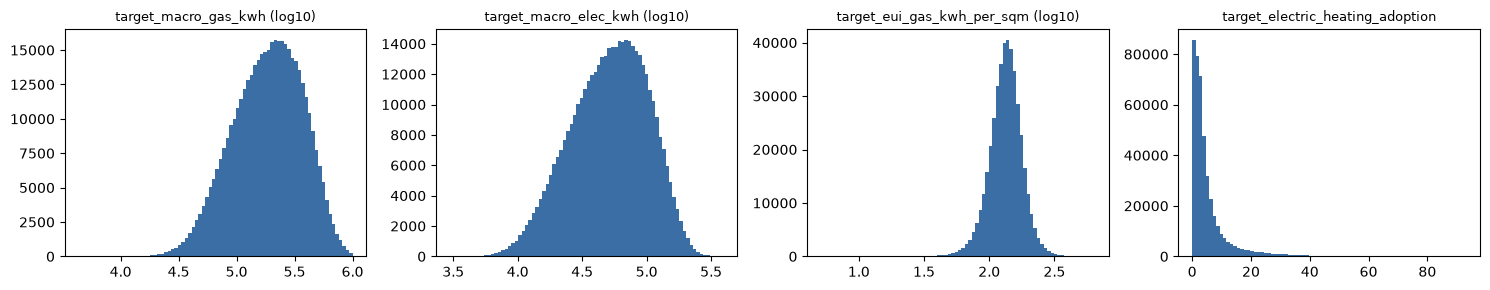

galat tiap target dibagi sigma berikut sebelum dirata-rata: {'target_macro_gas_kwh': 151750.04, 'target_macro_elec_kwh': 41725.37, 'target_eui_gas_kwh_per_sqm': 40.65, 'target_clean_building_ratio': 12.49, 'target_electric_heating_adoption': 7.18}


In [23]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3))
for ax, c in zip(axs, TARGET_COLS[:3] + [TARGET_COLS[4]]):
    v = tr[c].values
    ax.hist(np.log10(v) if c != TARGET_COLS[4] else v, bins=80, color="#3b6ea5")
    ax.set_title(c + (" (log10)" if c != TARGET_COLS[4] else ""), fontsize=9)
plt.tight_layout(); plt.show()
print("galat tiap target dibagi sigma berikut sebelum dirata-rata:", SIGMAS)

## 2. Fitur: menerjemahkan fisika dan geografi ke dalam angka
Pertanyaan yang memandu kami: apa yang membuat satu kawasan memakai energi lebih banyak dari kawasan lain?

**Ukuran rumah, bukan ukuran kawasan.** Gas total terutama mengikuti berapa banyak rumah di kawasan. Yang lebih
informatif adalah perilaku per rumah, jadi kami membuat rasio seperti luas lantai per meter (ukuran rata-rata rumah),
luas per sertifikat energi, dan sisa porsi jenis pemanas (sebagian besar pemanas listrik).

**Menebak per rumah.** Model menebak gas per meter, per meter persegi, per sertifikat, atau logaritmanya, lalu
hasilnya dikalikan kembali. Bobot tiap baris diatur supaya kesalahan yang dihukum tetap kesalahan pada skala asli.

**Rata-rata wilayah.** Kawasan yang berdekatan cenderung mirip. Kami memakai rata-rata target di subzona, zona, petak
iklim (gabungan tiga kolom iklim yang membentuk grid berisi sekitar 15 kawasan), dan kawasan di sekitar nomor subzona
yang berurutan secara geografis. Semuanya dihitung dari bagian data yang tidak sedang diuji, supaya model tidak
mencontek.

**Kawasan paling mirip.** Untuk setiap kawasan, kami mencari kawasan di sekitarnya yang stok bangunannya paling mirip
(ukuran rumah, cakupan sertifikat, campuran era bangunan) dan memakai rata-rata konsumsi mereka. Ini ide dengan efek
terbesar di proyek kami: galat EUI satu model turun 0,0022.

**Gambaran kawasan.** Jumlah kawasan, total luas, meter, dan sertifikat per subzona dan zona dari data latih dan uji
(tanpa target).

**Jumlah rumah tangga untuk adopsi.** Kolom campuran pemanas adalah pecahan cacah rumah tangga. Bilangan bulat terkecil
yang membuat semua pecahan utuh adalah jumlah rumah tangga, sehingga adopsi subzona baru bisa dimodelkan sebagai
peluang "berapa rumah dari K rumah memakai listrik".

Sel di bawah membangun fitur dasar dan gambaran kawasan, lalu menunjukkan kelompok fiturnya dan beberapa korelasi.

In [24]:
from train_lib import Data
d = Data()
ex, ext = d.agg_features()
fam = pd.Series([explain.family(c) for c in list(d.X.columns) + list(ex.columns)]).value_counts()
print("jumlah fitur per kelompok:"); print(fam.to_string())
demo = pd.DataFrame({"log EUI": np.log(tr[TARGET_COLS[2]]), "log luas per meter": np.log(d.X["area_per_meter"]),
                     "sisa porsi pemanas": d.X["hvac_rest"], "adopsi": tr[TARGET_COLS[4]]})
print("\nkorelasi beberapa fitur turunan dengan target:"); print(demo.corr().round(3).to_string())

jumlah fitur per kelompok:
sosio-demografi        118
dimensi bangunan        43
agregat kawasan         16
era bangunan            14
bauran pemanas          11
rasio fisik turunan     10
iklim                    5
lokasi                   2

korelasi beberapa fitur turunan dengan target:
                    log EUI  log luas per meter  sisa porsi pemanas  adopsi
log EUI               1.000              -0.347              -0.022  -0.032
log luas per meter   -0.347               1.000              -0.170  -0.147
sisa porsi pemanas   -0.022              -0.170               1.000   0.988
adopsi               -0.032              -0.147               0.988   1.000


## 3. Arsitektur: tiga jalur untuk lima target
* **Gas dan EUI** dilayani satu keluarga model. Saat menggabungkan model, bobot untuk kolom gas menekankan kawasan
  besar (yang paling menentukan galat gas), sedangkan bobot untuk kolom EUI tidak.
* **Listrik** punya keluarga model sendiri.
* **Porsi bangunan bersih** dihitung dengan rumus; **adopsi** disalin per subzona dan sisanya ditebak dengan model
  peluang.

Model yang dipakai sengaja beragam karena tiap jenis melihat data dengan cara berbeda: XGBoost dan LightGBM (pohon
keputusan bertingkat), beberapa jaringan saraf, dan NCA, jaringan yang belajar sendiri kawasan mana yang mirip lalu
menebak dari rata-rata kawasan mirip itu. Gabungannya memakai bobot tidak negatif yang berubah perlahan mengikuti luas
kawasan, jumlah meter, dan besar tebakan, karena model yang unggul di kawasan kecil belum tentu unggul di kawasan besar.

Setelah digabung, tebakan setiap kawasan digeser sedikit mengikuti rata-rata galat tetangga yang mirip (galat yang
masih berkorelasi antar kawasan berdekatan). Terakhir ada penyesuaian untuk dua batas di data: kawasan dengan 2 sampai
4 meter yang selalu ditebak terlalu rendah, dan gas yang di data latih tidak pernah melewati satu juta kWh. Semua
besaran untuk langkah setelah penggabungan ditentukan pada 30% data latih yang disisihkan sebagai ujian internal.

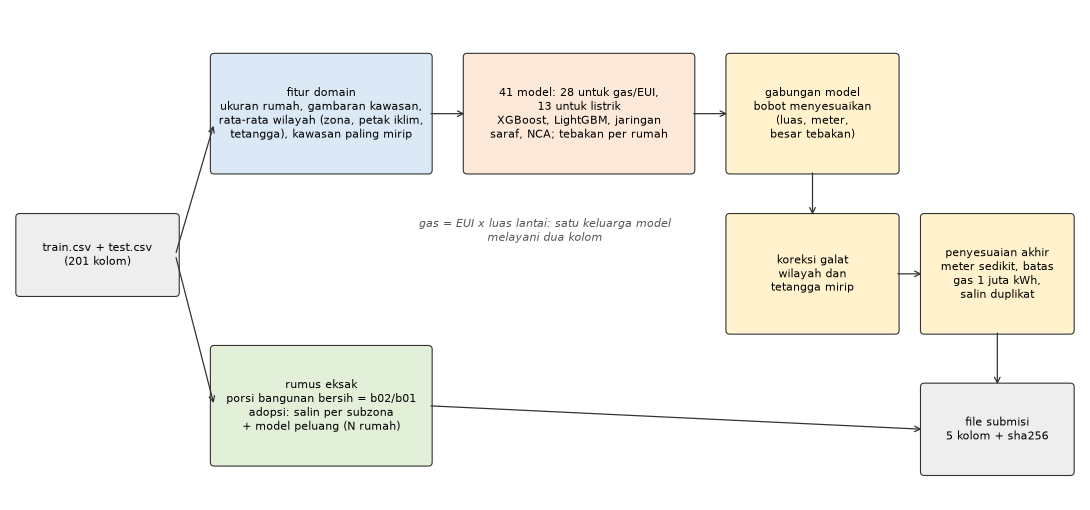

,anggota,model,keluarga,yang ditebak,bobot baris,fitur
0,xk_gpgea,XGBoost,gas / EUI,gas per luas selubung,1 / luas,dasar + rata-rata wilayah + kawasan mirip + ga...
1,mk1_epm,MLP gas + listrik,listrik,gas dan listrik per meter,-,dasar + rata-rata wilayah + kawasan mirip
2,xa_gpm,XGBoost,gas / EUI,gas per meter,1 / luas,dasar + rata-rata wilayah + gambaran kawasan
3,p1_gpm,MLP (PLR/TabM),gas / EUI,gas per meter,1 / luas,dasar + rata-rata wilayah
4,lgb_gas,LightGBM,gas / EUI,gas total,-,dasar
5,x8_gpn,XGBoost,gas / EUI,gas per sertifikat,1 / luas,dasar + rata-rata wilayah
6,n6_lgpm,MLP,gas / EUI,log gas per meter,luas,dasar + rata-rata wilayah
7,xgb_eui_wsM,XGBoost,gas / EUI,EUI,akar meter,dasar
8,la_gas,LightGBM,gas / EUI,gas total,-,dasar + rata-rata wilayah + gambaran kawasan
9,xgb_leui_wA,XGBoost,gas / EUI,log EUI,luas,dasar


In [25]:
report.architecture_diagram()
report.member_table(cfg)

## 4. Melatih semua model
Tiga proses berjalan paralel: jalur `xgb` (XGBoost di GPU), `nn` (jaringan saraf dan NCA di GPU), dan `cpu` (LightGBM).
Setiap model dilatih 10 kali (10 bagian data, seed 42) dan menyimpan tebakan untuk data latih (dari bagian yang tidak
ia lihat) dan data uji (rata-rata 10 model). Semua pustaka dipaksa deterministik, sehingga run ulang di hardware yang
sama memberi angka yang identik sampai byte terakhir.

*Catatan untuk salinan notebook ini:* sel pelatihan di bawah dilewati (`DICEFEST_TRAIN=0`) karena butuh sekitar 20 jam. Kami menjalankan pelatihannya terpisah dengan kode yang sama persis (modul di lampiran): ke-41 model dilatih ulang dari nol dan setiap tebakannya identik sampai byte terakhir dengan versi pengembangan. Sel-sel berikutnya memakai tebakan dari run itu, dan file submisi yang dihasilkan (sha256 di bagian 5) sama persis dengan file yang kami kirim. Jalankan dengan `DICEFEST_TRAIN=1` untuk melatih ulang semuanya.

In [26]:
import shutil
if TRAIN:
    if os.path.exists(WORK):
        shutil.rmtree(WORK)          # mulai dari kondisi bersih
    os.makedirs(WORK)
    t0 = time.time()
    procs = {}
    for lane in pipeline.LANES:   # XGBoost (GPU), jaringan saraf + NCA (GPU), LightGBM (CPU) paralel
        env = dict(os.environ, OMP_NUM_THREADS=pipeline.LANE_THREADS[lane])
        cmd = [sys.executable, "-u", "-c",
               f"import sys; sys.path.insert(0, {os.path.join(ROOT, 'src')!r}); import pipeline; "
               f"pipeline.run_members({lane!r}, {WORK!r})"]
        procs[lane] = subprocess.Popen(cmd, stdout=open(os.path.join(WORK, f"lane_{lane}.log"), "w"),
                                       stderr=subprocess.STDOUT, env=env)
    for lane, p in procs.items():
        rc = p.wait()
        print(f"jalur {lane} selesai rc={rc} setelah {(time.time() - t0) / 3600:.2f} jam")
        assert rc == 0, open(os.path.join(WORK, f"lane_{lane}.log")).read()[-3000:]
need = sorted(set(cfg["blend"]["gas"] + cfg["blend"]["elec"]))
missing = [m for m in need if not os.path.exists(os.path.join(WORK, "pred", m + ".npy"))]
print(len(need), "model di gabungan;", "semua tebakan tersedia" if not missing else f"belum ada: {missing}")

41 model di gabungan; semua tebakan tersedia


## 5. Menyusun file submisi
Model adopsi, penggabungan, koreksi galat wilayah, penyesuaian akhir, salinan 77 baris duplikat, lalu file submisi beserta sidik sha256-nya.

In [27]:
info = pipeline.run_adoption(WORK)
print(info)
sha = pipeline.assemble(WORK, OUT_CSV)
summary = json.load(open(os.path.join(WORK, "summary.json")))
print("sha256", sha)

  adoption fold 0 q_xent it=631


  adoption fold 0 r_reg it=444


  adoption fold 1 q_xent it=725


  adoption fold 1 r_reg it=1061


  adoption fold 2 q_xent it=433


...

blend honest CV {'gas': 0.24494174802833815, 'eui': 0.6502285547443805, 'elec': 0.315874614001809}


varying-coefficient blend {'gas': 'A2xM2xp2', 'eui': 'A2xM2xp2', 'elec': 'A2xM2xp2'}


gas correction rms/sigma 0.02047


eui correction rms/sigma 0.04344
elec correction rms/sigma 0.01195
post-processing S1 (small meters), S3 (gas truncation), S4 (train bounds) applied


wrote /root/Dicefest/final/nbrun_final/dicefest_nb/submission.csv sha256 aec745ab2114e6e196f3ea38b180771a4cc2df026a5d97f306b504eeeed0d66e
sha256 aec745ab2114e6e196f3ea38b180771a4cc2df026a5d97f306b504eeeed0d66e


## 6. Evaluasi
Skor jujur hasil penggabungan per kolom (bobot dihitung di empat per lima data, diuji di sisanya), lalu perjalanan skor
leaderboard. Setiap langkah dipilih dari ujian internal, dan leaderboard selalu membaik hampir persis sebesar
perkiraannya.

In [28]:
cv = summary["cv_blend_honest"]
print({k: round(v, 5) for k, v in cv.items()}, "(sebelum koreksi wilayah dan penyesuaian akhir)")
hist = pd.DataFrame([("v12", "gambaran kawasan + jaringan saraf PLR", 0.25025), ("v15", "koreksi galat wilayah", 0.24954),
                     ("v16", "fitur kawasan paling mirip di dalam model", 0.24943),
                     ("v19", "objektif Poisson + kawasan mirip lanjutan", 0.24934),
                     ("v19vc", "bobot gabungan yang menyesuaikan", 0.24925), ("v19nca", "model NCA", 0.24920),
                     ("final", "penyesuaian meter sedikit + batas gas", 0.24913)],
                    columns=["versi", "langkah", "LB publik"])
hist

{'gas': 0.24494, 'eui': 0.65023, 'elec': 0.31587} (sebelum koreksi wilayah dan penyesuaian akhir)


,versi,langkah,LB publik
0,v12,gambaran kawasan + jaringan saraf PLR,0.25025
1,v15,koreksi galat wilayah,0.24954
2,v16,fitur kawasan paling mirip di dalam model,0.24943
3,v19,objektif Poisson + kawasan mirip lanjutan,0.24934
4,v19vc,bobot gabungan yang menyesuaikan,0.24925
5,v19nca,model NCA,0.24920
6,final,penyesuaian meter sedikit + batas gas,0.24913


In [29]:
sub = pd.read_csv(OUT_CSV)
print(sub.shape)
sub.describe().T.round(3)

(183987, 6)


,count,mean,std,min,25%,50%,75%,max
target_macro_gas_kwh,183987.0,230751.325,147160.608,22187.949,116902.327,194513.382,310495.841,990541.642
target_macro_elec_kwh,183987.0,63914.506,39665.012,7495.993,32899.557,54644.079,85957.301,310449.536
target_eui_gas_kwh_per_sqm,183987.0,138.887,30.826,19.983,118.628,136.602,156.031,605.948
target_clean_building_ratio,183987.0,90.770,12.452,7.690,85.290,96.300,100.000,100.000
target_electric_heating_adoption,183987.0,5.387,7.177,0.000,1.550,3.101,6.098,82.687


## 7. Apa artinya bagi kebijakan
Gabungan 41 model terlalu rumit untuk dibaca, dan sebagian fiturnya (rata-rata target wilayah) bukan sesuatu yang
bisa diubah pembuat kebijakan. Karena itu kami melatih satu **model penjelas** per target yang hanya memakai
karakteristik kawasan yang bisa diukur: bangunan, era pembangunan, campuran pemanas, sosio-demografi, iklim, dan
gambaran kawasan.

Untuk membacanya kami memakai **SHAP**. Bayangkan tebakan model sebagai tumpukan sumbangan: dimulai dari rata-rata
nasional, lalu setiap fitur menambah atau mengurangi. SHAP menghitung besar sumbangan setiap fitur untuk setiap
kawasan secara adil. Kesetiaan model penjelas pada data ditunjukkan oleh R² pada data yang tidak ia lihat.

Nama kolom disamarkan panitia; makna yang kami tulis (misalnya `hvac_dist_02` sebagai porsi pemanas gas jaringan)
adalah dugaan dari pola datanya.

In [30]:
X, Xt = explain.feature_frame(d, ex, ext)
models, shap_res, summ = {}, {}, {}
for t, (label, fn) in explain.TARGETS.items():
    y = fn(tr)
    models[t], r2 = explain.fit_explain(X, y)
    shap_res[t] = explain.shap_values(models[t], X)
    summ[t] = dict(label=label, r2_holdout=round(r2, 3),
                   families=explain.family_shares(shap_res[t][1], list(X.columns)).round(4).to_dict())
pd.DataFrame({t: {"target": s["label"], "R2 pada data tak terlihat": s["r2_holdout"]} for t, s in summ.items()}).T

,target,R2 pada data tak terlihat
eui,log intensitas gas (EUI),0.563
gpm,log gas per meter,0.747
epm,log listrik per meter,0.491
adopt,adopsi pemanas listrik (%),0.991


Porsi sumbangan tiap kelompok fitur. Konsumsi gas dan listrik digerakkan oleh rasio fisik dan sosio-demografi; adopsi hampir seluruhnya oleh campuran jenis pemanas yang sudah ada.

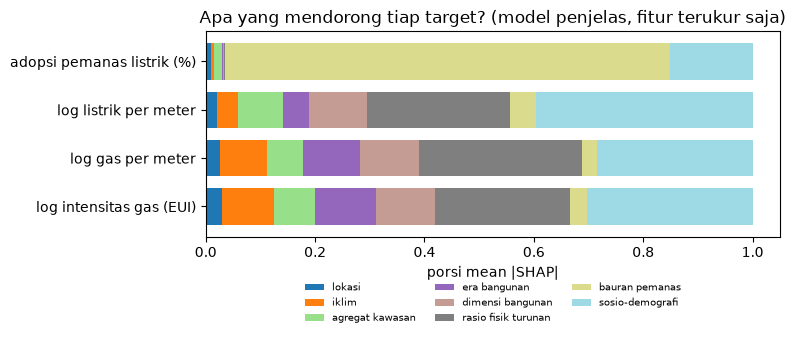

In [31]:
explain.plot_families(summ)

Sepuluh fitur dengan sumbangan terbesar untuk tiga target utama.

In [32]:
for t in ("eui", "epm", "adopt"):
    print(explain.TARGETS[t][0]); display(explain.top_features(shap_res[t][1], list(X.columns), k=10))

log intensitas gas (EUI)


,fitur,makna (dugaan),keluarga,mean |SHAP|
0,area_per_meter,luas lantai per meter (ukuran hunian),rasio fisik turunan,0.0895
1,env_climate_05,,iklim,0.0321
2,socio_demog_082,,sosio-demografi,0.0276
3,area_per_epc,luas per sertifikat,rasio fisik turunan,0.0260
4,s002_ratio,,rasio fisik turunan,0.0250
5,bld_era_15,,era bangunan,0.0198
6,socio_demog_005,,sosio-demografi,0.0184
7,bld_era_09,,era bangunan,0.0153
8,socio_demog_038,,sosio-demografi,0.0147
9,env_climate_02,,iklim,0.0141


log listrik per meter


,fitur,makna (dugaan),keluarga,mean |SHAP|
0,area_per_meter,luas lantai per meter (ukuran hunian),rasio fisik turunan,0.0895
1,meters_per_epc,meter per sertifikat,rasio fisik turunan,0.0294
2,socio_demog_005,,sosio-demografi,0.0222
3,socio_demog_038,,sosio-demografi,0.0196
4,socio_demog_061,,sosio-demografi,0.0163
5,hvac_rest,sisa pangsa (listrik + lain-lain),bauran pemanas,0.0157
6,socio_demog_064,,sosio-demografi,0.0117
7,bld_dim_32,,dimensi bangunan,0.0111
8,env_climate_02,,iklim,0.0109
9,socio_demog_090,,sosio-demografi,0.0108


adopsi pemanas listrik (%)


,fitur,makna (dugaan),keluarga,mean |SHAP|
0,hvac_rest,sisa pangsa (listrik + lain-lain),bauran pemanas,3.5653
1,hvac_dist_02,gas jaringan (sentral),bauran pemanas,0.9053
2,hvac_dist_09,dua jenis+ (non-terbarukan),bauran pemanas,0.2691
3,hvac_dist_01,tanpa pemanas sentral,bauran pemanas,0.0968
4,hvac_dist_08,jaringan panas distrik,bauran pemanas,0.0953
5,socio_demog_035,,sosio-demografi,0.0883
6,hvac_dist_04,minyak,bauran pemanas,0.0816
7,hvac_dist_03,tangki/LPG,bauran pemanas,0.0697
8,socio_demog_082,,sosio-demografi,0.0649
9,socio_demog_024,,sosio-demografi,0.0575


Bagaimana sumbangan berubah mengikuti nilai fitur. Setiap titik adalah satu kawasan, garis merah adalah rata-ratanya.

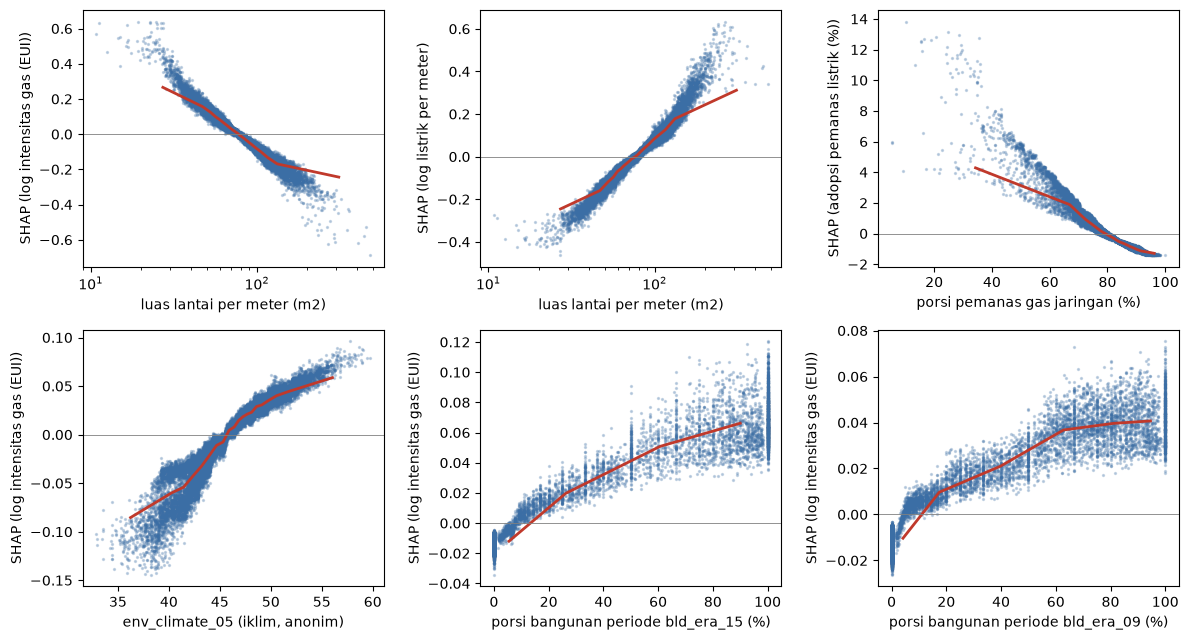

In [33]:
explain.plot_dependence(X, shap_res, [
    ("eui", "area_per_meter", "luas lantai per meter (m2)", True),
    ("epm", "area_per_meter", "luas lantai per meter (m2)", True),
    ("adopt", "hvac_dist_02", "porsi pemanas gas jaringan (%)", False),
    ("eui", "env_climate_05", "env_climate_05 (iklim, anonim)", False),
    ("eui", "bld_era_15", "porsi bangunan periode bld_era_15 (%)", False),
    ("eui", "bld_era_09", "porsi bangunan periode bld_era_09 (%)", False)])

### 7.1 Membaca grafik di atas
* **Ukuran rumah bekerja ke arah berlawanan untuk gas dan listrik.** Rumah kecil memakai gas per meter persegi sekitar
  65% lebih banyak daripada rumah besar, karena dinding dan atapnya relatif luas dibanding ruang yang dipanaskan.
  Sebaliknya, rumah besar memakai listrik per rumah sekitar 75% lebih banyak.
* **Bangunan dari periode tertentu lebih boros** (hingga sekitar 7% EUI), dan **iklim** menggeser EUI sekitar 15%.
  Inilah bagian konsumsi yang bisa dipangkas lewat perbaikan dinding, atap, dan jendela.
* **Adopsi pemanas listrik ditentukan infrastruktur yang ada.** Porsi pemanas gas jaringan yang tinggi menekan adopsi;
  faktor sosio-demografi hanya menyumbang sekitar 15%.

### 7.2 Peta trilema per zona
Untuk menjadikan temuan ini daftar kerja, kami menggabungkan nilai sebenarnya (kawasan latih) dan tebakan akhir
(kawasan uji), lalu meringkasnya ke 330 zona dengan dua ukuran: **potensi hemat dari perbaikan bangunan** (gas yang
hilang bila sumbangan stok bangunan di atas rata-rata nasional dihapus) dan **kenaikan beban listrik bila pemanas gas
diganti pompa panas listrik** (asumsi: 80% gas untuk pemanasan, 1 kWh listrik menghasilkan 3 kWh panas).

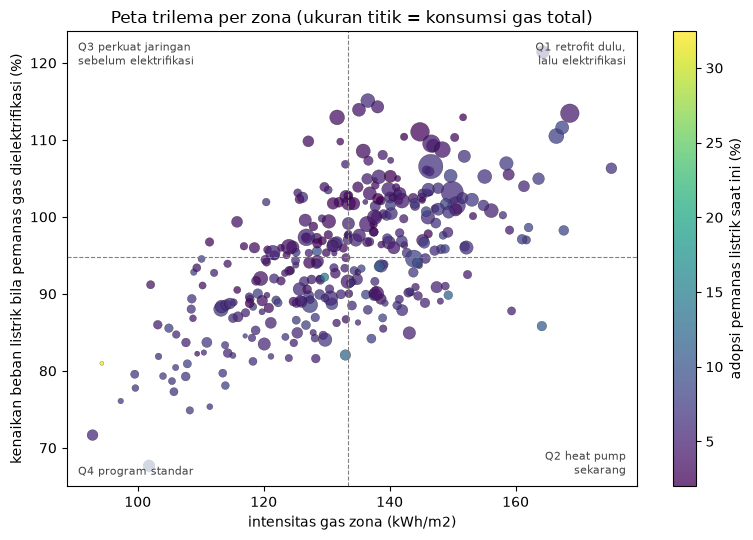

,zona,gas_TWh,hemat_retrofit_TWh,adopsi_rata2,kenaikan_beban_rata2_pct,porsi_gas,kebijakan
kuadran,,,,,,,
Q1,118,66.095,3.650,5.145,102.494,0.468,"retrofit selubung dulu, lalu elektrifikasi ber..."
Q2,47,16.299,1.073,6.185,90.245,0.115,percepat heat pump sekarang (jaringan masih lo...
Q3,47,20.607,0.858,4.093,99.102,0.146,perkuat gardu dan tarif fleksibel sebelum elek...
Q4,118,38.354,1.810,5.983,87.042,0.271,program standar berbasis pasar


In [34]:
sub_best = pd.read_csv(OUT_CSV)
Z = explain.zone_indices(models["eui"], X, Xt, tr, te, sub_best)
q = explain.quadrant_table(Z)
explain.plot_trilemma(Z)
q.round(3)

In [35]:
tot = dict(gas_TWh=Z.gas.sum() / 1e9, potensi_hemat_bangunan_TWh=Z.gas_saving.sum() / 1e9,
           potensi_hemat_pct=100 * Z.gas_saving.sum() / Z.gas.sum(),
           kenaikan_beban_median_pct=Z.load_increase_pct.median())
print({k: round(v, 2) for k, v in tot.items()})
cols_show = ["gas", "eui", "adopt", "gas_network_share", "saving_pct", "load_increase_pct", "kuadran"]
print("10 zona dengan potensi hemat bangunan terbesar (kWh):")
display(Z.sort_values("gas_saving", ascending=False).head(10)[cols_show].round(2))
print("10 zona dengan kenaikan beban listrik terbesar bila pemanas dielektrifikasi:")
display(Z.sort_values("load_increase_pct", ascending=False).head(10)[cols_show].round(2))

{'gas_TWh': np.float64(141.35), 'potensi_hemat_bangunan_TWh': np.float64(7.39), 'potensi_hemat_pct': np.float64(5.23), 'kenaikan_beban_median_pct': np.float64(94.85)}
10 zona dengan potensi hemat bangunan terbesar (kWh):


,gas,eui,adopt,gas_network_share,saving_pct,load_increase_pct,kuadran
zone,,,,,,,
REG_273,2.311622e+09,149.95,5.80,82.09,7.36,103.18,Q1
REG_270,1.627015e+09,168.61,4.46,82.03,8.60,113.46,Q1
REG_045,1.655768e+09,144.82,2.60,83.58,6.69,111.05,Q1
REG_242,1.378593e+09,143.85,7.99,77.11,7.35,94.57,Q2
REG_263,2.838367e+09,146.52,6.40,79.81,3.43,106.54,Q1
REG_258,1.433624e+09,146.62,4.10,83.80,6.17,109.52,Q1
REG_240,8.956034e+08,156.13,4.88,83.19,9.34,100.81,Q1
REG_249,9.098435e+08,137.94,3.75,85.54,9.13,90.07,Q2
REG_023,1.131829e+09,127.33,7.85,81.17,7.28,88.58,Q4


10 zona dengan kenaikan beban listrik terbesar bila pemanas dielektrifikasi:


,gas,eui,adopt,gas_network_share,saving_pct,load_increase_pct,kuadran
zone,,,,,,,
REG_290,7.146263e+08,164.34,6.08,82.28,3.57,121.41,Q1
REG_259,8.904616e+08,136.54,5.88,80.70,2.70,115.10,Q1
REG_275,6.888743e+08,138.08,4.02,83.26,4.32,114.29,Q1
REG_260,7.690931e+08,135.12,3.73,84.80,3.60,113.91,Q1
REG_270,1.627015e+09,168.61,4.46,82.03,8.60,113.46,Q1
REG_330,1.799969e+08,151.66,2.39,85.21,7.03,112.93,Q1
REG_262,1.011766e+09,131.66,3.42,81.62,3.75,112.92,Q3
REG_280,7.846541e+08,167.39,8.40,76.40,5.07,111.60,Q1
REG_045,1.655768e+09,144.82,2.60,83.58,6.69,111.05,Q1


### 7.3 Rekomendasi
1. **Urutkan program per kelompok zona, jangan seragamkan.** Kelompok Q1 (boros dan jaringan rawan) memuat hampir
   separuh konsumsi gas dan separuh potensi hemat bangunan. Di sini perbaikan bangunan harus datang sebelum pompa
   panas: kebutuhan panas yang turun lebih dulu memangkas tagihan dan emisi, sekaligus mengecilkan lonjakan beban
   listrik saat elektrifikasi masuk.
2. **Jadikan Q2 kemenangan cepat untuk pompa panas.** Intensitas gasnya tinggi tetapi jaringan masih punya ruang.
3. **Ajak operator jaringan sejak awal di Q1 dan Q3.** Zona dengan kenaikan beban lebih dari dua kali lipat butuh
   penguatan gardu, tarif berdasarkan waktu pemakaian, atau pompa panas dengan penyimpan panas sebelum subsidi besar.
4. **Beri insentif khusus untuk kawasan yang sudah tersambung gas**, karena tanpa dorongan adopsi di sana nyaris nol.
5. **Pisahkan target efisiensi dan target emisi.** Rumah kecil boros per meter persegi, rumah besar boros per rumah.

**Batasan.** SHAP menunjukkan hubungan dalam data, bukan sebab-akibat yang pasti. Skenario beban listrik adalah
perhitungan fisika sederhana di atas tebakan model; urutan antar zona lebih bisa dipegang daripada angka mutlaknya.

## 8. Penutup
* Memahami data lebih dulu menyelesaikan dua target tanpa model dan menentukan arah seluruh pekerjaan.
* Perbaikan terbesar datang dari informasi tetangga yang dihitung dengan jujur: rata-rata wilayah, kawasan paling mirip,
  dan koreksi galat wilayah. Sisanya dari keragaman model dan penggabungan yang menyesuaikan.
* Setiap perubahan dipilih dari ujian internal yang terbukti memperkirakan leaderboard, bukan dari leaderboard itu sendiri.
* Model yang sama bisa diubah menjadi peta prioritas yang langsung bisa dipakai: zona mana yang perlu dibenahi
  bangunannya dulu, mana yang siap beralih ke listrik, dan mana yang jaringannya harus diperkuat lebih dulu.